# Amazon Reviews 2023 - Beauty Category - Sentiment Analysis

This notebook builds a clean, unbiased, and reproducible pipeline for a
sentiment analysis project on the **All Beauty** subset of the
Amazon Reviews 2023 dataset (https://amazon-reviews-2023.github.io/).

**Pipeline overview:**
1. Install & import libraries
2. Load reviews + metadata
3. Merge datasets and create the sentiment target
4. Clean the merged dataframe (drop leakage/unneeded columns, duplicates, nulls)
5. Draw a stratified (unbiased) sample from the full dataset
6. Split into train / validation / test (stratified)
7. Exploratory Data Analysis (EDA)
8. Text preprocessing - two separate pipelines:
   - Classical ML pipeline (TF-IDF based models)
   - Transformer pipeline (DistilBERT / BERT / RoBERTa)
9. Preparing data for a transformer model (tokenization)


## 1. Install & import required libraries

In [ ]:
# Install the datasets library (only needed once per environment)
!pip install datasets==2.20.0 -q
!pip install scikit-learn nltk wordcloud matplotlib seaborn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.8/547.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.1/316.1 kB 16.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.5.0 which is incompatible.


In [ ]:
# Core libraries
import re
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# ML
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Download NLTK resources (only needed once)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 2. Load the reviews dataset (All Beauty)

In [ ]:
from datasets import load_dataset

# Load raw reviews for the "All Beauty" category
dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_review_All_Beauty",
    trust_remote_code=True
)

# Quick look at a single example
print(dataset["full"][0])


Generating full split: 0 examples [00:00, ? examples/s]

{'rating': 5.0, 'title': 'Such a lovely scent but not overpowering.', 'text': "This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, medium thickness. I am comparing to other brands with yucky chemicals so I'm gonna stick with this. Try it!", 'images': [], 'asin': 'B00YQ6X8EO', 'parent_asin': 'B00YQ6X8EO', 'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'timestamp': 1588687728923, 'helpful_vote': 0, 'verified_purchase': True}


In [ ]:
df = pd.DataFrame(dataset["full"])
print("Reviews shape:", df.shape)
df.head(3)


Reviews shape: (701528, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True


## 3. Load the metadata dataset (product info) and merge

In [ ]:
dataset_meta = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_meta_All_Beauty",
    trust_remote_code=True
)
df_meta = pd.DataFrame(dataset_meta["full"])
print("Metadata shape (before dedup):", df_meta.shape)


Generating full split:   0%|          | 0/112590 [00:00<?, ? examples/s]

Metadata shape (before dedup): (112590, 16)


In [ ]:
# FIX #1: the metadata table can have multiple rows for the same parent_asin.
# If we merge without deduplicating first, review rows get duplicated during the
# left join, which silently inflates the dataset and biases any downstream sample.
n_dup_products = df_meta["parent_asin"].duplicated().sum()
print("Duplicated parent_asin rows in metadata:", n_dup_products)

df_meta = df_meta.drop_duplicates(subset="parent_asin", keep="first")
print("Metadata shape (after dedup):", df_meta.shape)


Duplicated parent_asin rows in metadata: 0
Metadata shape (after dedup): (112590, 16)


In [ ]:
# Merge reviews with product metadata on parent_asin
merged_df = pd.merge(df, df_meta, on="parent_asin", how="left")
print("Merged shape:", merged_df.shape)

# Sanity check: merged row count should equal the original reviews row count
# now that metadata duplicates were removed.
assert merged_df.shape[0] == df.shape[0], "Merge produced extra rows - check for duplicate keys."


Merged shape: (701528, 25)


In [ ]:
# Create the sentiment target directly from the numeric rating
sentiment_mapping = {
    1.0: "Very Negative",
    2.0: "Negative",
    3.0: "Neutral",
    4.0: "Positive",
    5.0: "Very Positive"
}
merged_df["sentiment"] = merged_df["rating"].map(sentiment_mapping)
merged_df["sentiment"].value_counts()


,count
sentiment,
Very Positive,420726
Very Negative,102080
Positive,79381
Neutral,56307
Negative,43034


## 4. Cleaning the merged dataframe



In [ ]:
# Merge review title and review text into a single text column
merged_df["review"] = (
    merged_df["title_x"].fillna("").astype(str)
    + " "
    + merged_df["text"].fillna("").astype(str)
)


In [ ]:
# Drop columns that are not useful for sentiment analysis
columns_to_drop = [
    "images_x",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "images_y",
    "videos",
    "categories",
    "bought_together",
    "subtitle",
    "author",
    "title_x",
    "text",
]
merged_df.drop(columns=columns_to_drop, inplace=True)
print(merged_df.columns.tolist())


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'price', 'store', 'details', 'sentiment', 'review']


In [ ]:
# Drop rows with an empty review after merging title + text
before = merged_df.shape[0]
merged_df = merged_df[
    merged_df["review"].notna() & (merged_df["review"].str.strip() != "")
].copy()
print(f"Dropped {before - merged_df.shape[0]} rows with empty reviews.")


Dropped 0 rows with empty reviews.


In [ ]:
# Remove duplicate reviews (exact text duplicates, e.g. copy-pasted or spam reviews)
before = merged_df.shape[0]
merged_df.drop_duplicates(subset=["review"], inplace=True)
print(f"Dropped {before - merged_df.shape[0]} duplicate reviews.")


Dropped 29904 duplicate reviews.


In [ ]:
# Remove reviews that are too short to carry sentiment information (< 3 words)
before = merged_df.shape[0]
merged_df = merged_df[merged_df["review"].str.split().str.len() >= 3].copy()
print(f"Dropped {before - merged_df.shape[0]} reviews shorter than 3 words.")


Dropped 2776 reviews shorter than 3 words.


In [ ]:
# Check remaining missing values
merged_df.isnull().sum().sort_values(ascending=False)


,0
store,46889
rating,0
verified_purchase,0
main_category,0
title_y,0
helpful_vote,0
average_rating,0
rating_number,0
description,0
features,0


In [ ]:
# 'store' has too many missing values and is not useful for sentiment analysis
merged_df.drop(columns=["store"], inplace=True)


In [ ]:
# FIX #3: price was stored as an object (mixed types like the string "None").
# Convert to numeric and inspect how many values are missing.
merged_df["price"] = pd.to_numeric(merged_df["price"], errors="coerce")
print("Missing price values:", merged_df["price"].isnull().sum())

# price is not relevant to sentiment and has too many missing values -> drop it
merged_df.drop(columns=["price"], inplace=True)


Missing price values: 492294


In [ ]:
print(merged_df.columns.tolist())
print(merged_df.shape)
merged_df.isnull().sum()


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'details', 'sentiment', 'review']
(668848, 12)


,0
rating,0
helpful_vote,0
verified_purchase,0
main_category,0
title_y,0
average_rating,0
rating_number,0
features,0
description,0
details,0


In [ ]:
merged_df.head()

,rating,helpful_vote,verified_purchase,main_category,title_y,average_rating,rating_number,features,description,details,sentiment,review
0,5.0,0,True,All Beauty,Herbivore - Natural Sea Mist Texturizing Salt ...,4.3,384,[],"[If given the choice, weÕd leave most telltale...","{""Hair Type"": ""Wavy"", ""Material Type Free"": ""D...",Very Positive,Such a lovely scent but not overpowering. This...
1,4.0,1,True,All Beauty,All Natural Vegan Dry Shampoo Powder - Eco Fri...,4.0,56,[],[],"{""Brand"": ""Two Goats Apothecary"", ""Item Form"":...",Positive,Works great but smells a little weird. This pr...
2,5.0,2,True,All Beauty,New Road Beauty - Creamsicle - Variety 3 Pack ...,4.4,699,"[Same Great Product, NEW PACKAGING., MOISTURIZ...",[New Road Beauty Paraffin Wax is recommended f...,"{""Package Dimensions"": ""10.5 x 6.4 x 1.6 inche...",Very Positive,"Yes! Smells good, feels great!"
3,1.0,0,True,All Beauty,muaowig Ombre Body Wave Bundles 1B Grey Human ...,1.0,1,[?Hair Bundle Material?:Brazilian Virgin Human...,[Hair Material: Brazilian Virgin Human Hair Bu...,"{""Brand"": ""muaowig"", ""Material"": ""Human Hair"",...",Very Negative,Synthetic feeling Felt synthetic
4,5.0,0,True,All Beauty,Yinhua Electric Nail Drill Kit Portable Profes...,3.5,20,[],[],"{""Package Dimensions"": ""8.5 x 3.82 x 2.24 inch...",Very Positive,A+ Love it


## 5. Draw an unbiased (stratified) sample

The full dataset has ~600K+ rows and is heavily imbalanced (Very Positive ~59%,
Negative ~6%). To keep a manageable, representative sample, we use
**stratified sampling**: the class proportions in the sample match the
proportions in the full dataset, so the sample is not biased toward any
particular sentiment.


In [ ]:
SAMPLE_SIZE = 100_000  # adjust based on available compute

sample_df, _ = train_test_split(
    merged_df,
    train_size=SAMPLE_SIZE,
    stratify=merged_df["sentiment"],
    random_state=RANDOM_STATE
)

print("Full dataset proportions:")
print(merged_df["sentiment"].value_counts(normalize=True) * 100)
print("\nSample proportions:")
print(sample_df["sentiment"].value_counts(normalize=True) * 100)


Full dataset proportions:
sentiment
Very Positive    59.132419
Very Negative    14.922374
Positive         11.405581
Neutral           8.216516
Negative          6.323111
Name: proportion, dtype: float64

Sample proportions:
sentiment
Very Positive    59.132
Very Negative    14.922
Positive         11.406
Neutral           8.217
Negative          6.323
Name: proportion, dtype: float64


## 6. Train / Validation / Test split (stratified)

In [ ]:
train_df, temp_df = train_test_split(
    sample_df,
    test_size=0.30,
    stratify=sample_df["sentiment"],
    random_state=RANDOM_STATE
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["sentiment"],
    random_state=RANDOM_STATE
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


Train: (70000, 12)
Validation: (15000, 12)
Test: (15000, 12)


## 7. Exploratory Data Analysis (EDA)

Every plot here is meant to inform a concrete decision later on (class
balancing strategy, model input length, feature quality, etc.), not just for
display.


### 7.1 Class distribution (target balance)

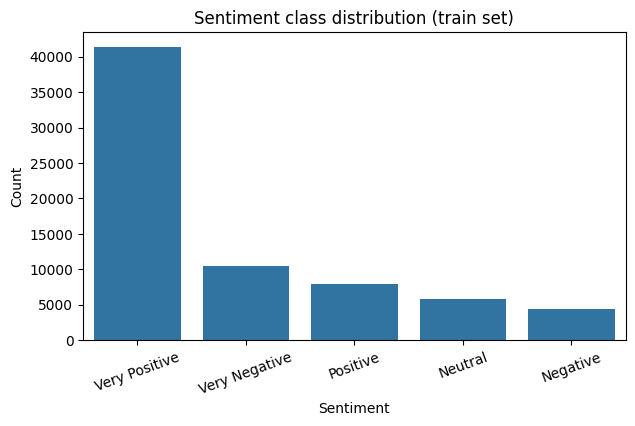

,proportion
sentiment,
Very Positive,59.131429
Very Negative,14.922857
Positive,11.405714
Neutral,8.217143
Negative,6.322857


In [ ]:
plt.figure(figsize=(7, 4))
order = train_df["sentiment"].value_counts().index
sns.countplot(data=train_df, x="sentiment", order=order)
plt.title("Sentiment class distribution (train set)")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

train_df["sentiment"].value_counts(normalize=True) * 100


### 7.2 Review length distribution per class

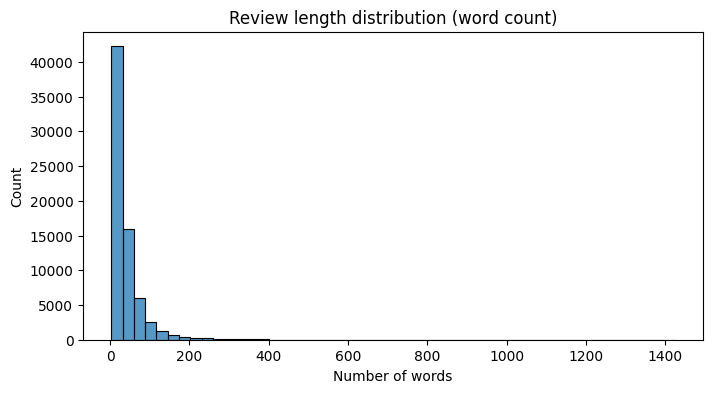

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,4426.0,41.946905,44.976741,3.0,16.0,30.0,52.0,598.0
Neutral,5752.0,43.259736,49.003316,3.0,15.0,30.0,52.0,721.0
Positive,7984.0,48.258016,57.792625,3.0,15.0,31.0,58.0,952.0
Very Negative,10446.0,34.773310,38.454839,3.0,13.0,25.0,43.0,1424.0
Very Positive,41392.0,35.453759,45.271347,3.0,11.0,22.0,43.0,1190.0


In [ ]:
train_df["review_len"] = train_df["review"].str.split().str.len()

plt.figure(figsize=(8, 4))
sns.histplot(data=train_df, x="review_len", bins=50)
plt.title("Review length distribution (word count)")
plt.xlabel("Number of words")
plt.show()

train_df.groupby("sentiment")["review_len"].describe()


### 7.3 Most frequent words per sentiment class

In [ ]:
from collections import Counter

stop_words = set(stopwords.words("english"))

def get_top_words(text_series, n=15):
    words = " ".join(text_series.astype(str)).lower().split()
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return Counter(words).most_common(n)

for label in train_df["sentiment"].unique():
    subset = train_df[train_df["sentiment"] == label]["review"]
    print(f"--- Top words for: {label} ---")
    print(get_top_words(subset))
    print()


--- Top words for: Positive ---
[('good', 2500), ('like', 2388), ('hair', 2147), ('great', 2138), ('product', 1526), ('use', 1523), ('love', 1328), ('would', 1289), ('really', 1287), ('nice', 1270), ('little', 1241), ('one', 1169), ('stars', 1086), ('get', 1044), ('works', 998)]

--- Top words for: Very Positive ---
[('great', 14808), ('love', 14272), ('hair', 9909), ('good', 7301), ('product', 7238), ('use', 6622), ('like', 6544), ('really', 4804), ('easy', 4474), ('works', 4348), ('one', 4240), ('stars', 4043), ('five', 4013), ('skin', 3981), ('nice', 3778)]

--- Top words for: Negative ---
[('like', 1178), ('hair', 1168), ('product', 695), ('would', 684), ('use', 660), ('get', 647), ('one', 643), ('two', 613), ('good', 592), ('really', 520), ('work', 484), ('stars', 477), ('used', 403), ('even', 380), ('much', 361)]

--- Top words for: Neutral ---
[('like', 1624), ('hair', 1508), ('good', 1118), ('use', 954), ('product', 951), ('would', 895), ('get', 793), ('really', 781), ('one', 7

### 7.4 verified_purchase vs sentiment

In [ ]:
pd.crosstab(
    train_df["verified_purchase"], train_df["sentiment"], normalize="index"
) * 100


sentiment,Negative,Neutral,Positive,Very Negative,Very Positive
verified_purchase,,,,,
False,5.249699,7.415764,16.200361,11.823105,59.311071
True,6.435472,8.301238,10.902576,15.248137,59.112577


### 7.5 helpful_vote vs sentiment

In [ ]:
train_df.groupby("sentiment")["helpful_vote"].describe()


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,4426.0,0.809083,4.099268,0.0,0.0,0.0,1.0,133.0
Neutral,5752.0,0.655598,2.320620,0.0,0.0,0.0,1.0,60.0
Positive,7984.0,0.984218,6.467642,0.0,0.0,0.0,1.0,431.0
Very Negative,10446.0,0.992246,4.740144,0.0,0.0,0.0,1.0,192.0
Very Positive,41392.0,0.959098,5.784568,0.0,0.0,0.0,1.0,467.0


### 7.7 Bigrams per sentiment class (visual)

Single words like "good" or "bad" don't capture negation or context
(e.g. "not good", "waste of money"). Bigrams give a clearer picture of what
actually drives each sentiment.


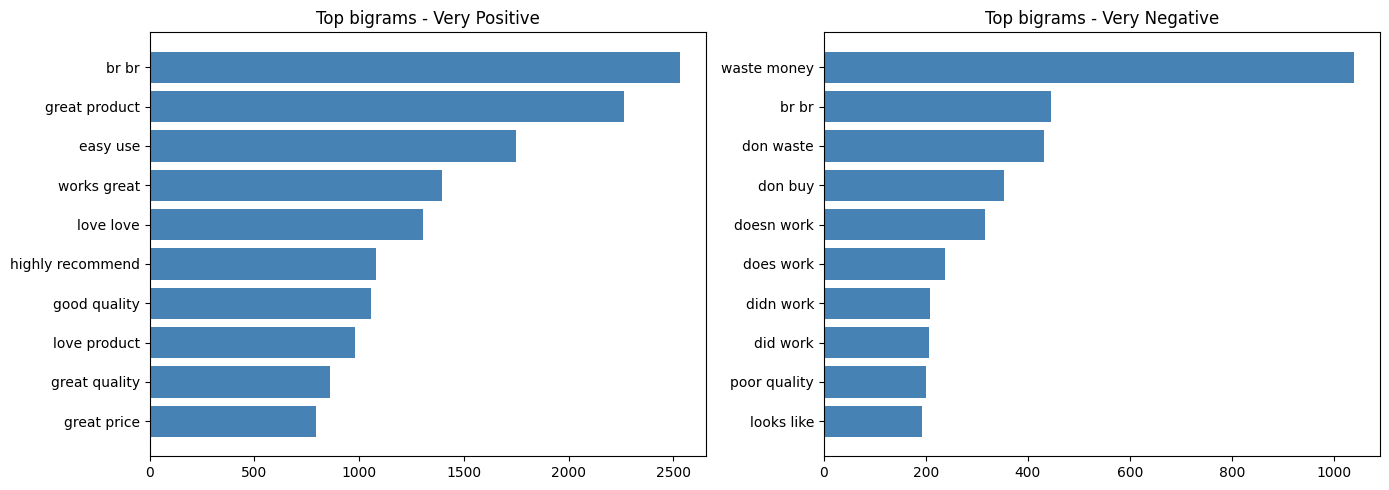

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def plot_top_bigrams(df_subset, label, ax, n=10):
    cv = CountVectorizer(ngram_range=(2, 2), stop_words="english", max_features=n)
    bigram_matrix = cv.fit_transform(df_subset["review"].astype(str))
    counts = bigram_matrix.sum(axis=0).A1
    bigrams = cv.get_feature_names_out()
    order = np.argsort(counts)[::-1]
    ax.barh([bigrams[i] for i in order][::-1], [counts[i] for i in order][::-1], color="steelblue")
    ax.set_title(f"Top bigrams - {label}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_top_bigrams(train_df[train_df["sentiment"] == "Very Positive"], "Very Positive", axes[0])
plot_top_bigrams(train_df[train_df["sentiment"] == "Very Negative"], "Very Negative", axes[1])
plt.tight_layout()
plt.show()


### 7.8 main_category vs sentiment (visual)

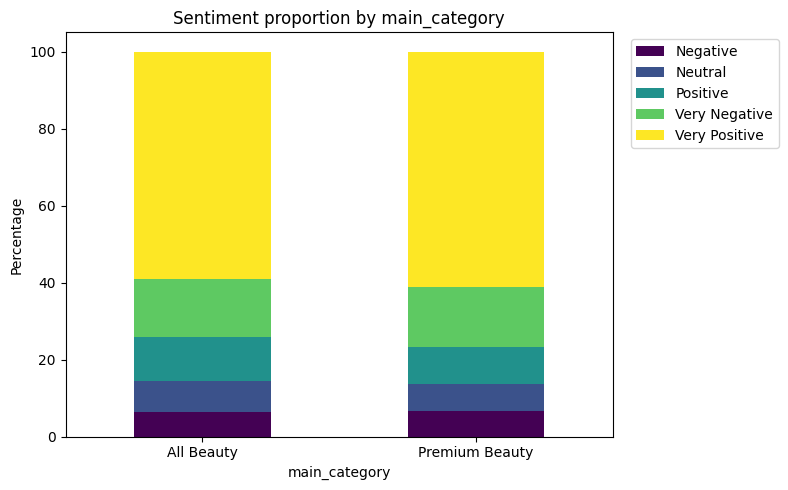

,count
main_category,
All Beauty,69222
Premium Beauty,778


In [ ]:
cross = pd.crosstab(train_df["main_category"], train_df["sentiment"], normalize="index") * 100

cross.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Sentiment proportion by main_category")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

train_df["main_category"].value_counts()


### 7.9 Emoji presence check

Emojis can carry strong sentiment signal. We check how common they are before
deciding whether to strip them (classical ML) or keep them (transformer
pipeline, where they can still add signal).


In [ ]:
import re as _re

emoji_pattern = _re.compile(
    "["
    "\U0001F300-\U0001FAFF"
    "\U00002700-\U000027BF"
    "\U00002600-\U000026FF"
    "]+",
    flags=_re.UNICODE
)

train_df["has_emoji"] = train_df["review"].astype(str).apply(lambda t: bool(emoji_pattern.search(t)))
print("Reviews containing emoji:", train_df["has_emoji"].sum(), f"({train_df['has_emoji'].mean()*100:.2f}%)")

pd.crosstab(train_df["has_emoji"], train_df["sentiment"], normalize="index") * 100


Reviews containing emoji: 1835 (2.62%)


sentiment,Negative,Neutral,Positive,Very Negative,Very Positive
has_emoji,,,,,
False,6.396244,8.296046,11.473630,14.951955,58.882124
True,3.596730,5.286104,8.882834,13.841962,68.392371


### 7.10 Neutral vs neighboring classes - word overlap check

If Neutral shares most of its top words with Positive/Negative, the language
boundary between classes is weak, and merging into 3 classes
(Negative / Neutral / Positive) may give a stronger, more learnable model.


In [ ]:
neutral_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Neutral"]["review"], n=30))
positive_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Positive"]["review"], n=30))
negative_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Negative"]["review"], n=30))

print("Overlap Neutral/Positive:", neutral_words & positive_words)
print("Overlap Neutral/Negative:", neutral_words & negative_words)


Overlap Neutral/Positive: {'love', 'color', 'much', 'pretty', 'product', 'long', 'little', 'nice', 'hair', 'use', 'really', 'great', 'like', 'good', 'stars', 'well', 'still', 'using', 'get', 'used', 'one', 'work', 'would', 'works'}
Overlap Neutral/Negative: {'color', 'much', 'product', 'hair', 'use', 'really', 'great', 'like', 'good', 'stars', 'well', 'small', 'brush', 'using', 'get', 'used', 'one', 'work', 'would'}


## 8. Text preprocessing

Preprocessing is **not one-size-fits-all**. We build two separate cleaning
pipelines depending on which model family will consume the text:

- **Classical ML (TF-IDF + Logistic Regression / SVM / Naive Bayes)**:
  needs aggressive normalization - lowercasing, punctuation removal,
  stopword removal, lemmatization. These models only see word frequencies,
  so removing noise words and merging word forms helps a lot.

- **Transformer models (DistilBERT / BERT / RoBERTa)**:
  needs light cleaning only - keep punctuation, casing information and
  stopwords, since the model's own subword tokenizer and attention
  mechanism already handle context, negation and word forms. Aggressive
  cleaning here actually *hurts* performance.


### 8.1 Shared basic cleaning (applies to both pipelines)

In [ ]:
def basic_clean(text):
    """Light cleaning shared by every pipeline: remove links, HTML tags,
    and collapse extra whitespace. Keeps punctuation and casing intact."""
    text = re.sub(r"http\S+|www\S+", " ", text)   # URLs
    text = re.sub(r"<.*?>", " ", text)               # HTML tags
    text = re.sub(r"\s+", " ", text).strip()         # extra whitespace
    return text

for split_df in [train_df, val_df, test_df]:
    split_df["review_basic"] = split_df["review"].apply(basic_clean)


### 8.2 Classical ML preprocessing (TF-IDF pipeline)

In [ ]:
lemmatizer = WordNetLemmatizer()

def clean_for_classical_ml(text):
    """Aggressive cleaning for TF-IDF based models:
    lowercase -> remove punctuation/numbers -> remove stopwords -> lemmatize."""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)            # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return " ".join(tokens)

for split_df in [train_df, val_df, test_df]:
    split_df["review_clf_ml"] = split_df["review_basic"].apply(clean_for_classical_ml)

train_df[["review", "review_clf_ml"]].head(3)


,review,review_clf_ml
328723,Good Purchase Is a Christmas gift. Don't know...,good purchase christmas gift know well hold ye...
246525,Saved my mouth when I didn't yet have insuranc...,saved mouth yet insurance half tooth fell x x ...
606291,Great product Really makes a difference in my ...,great product really make difference hair alre...


### 8.3 Transformer preprocessing (DistilBERT / BERT / RoBERTa)

Only the shared basic cleaning (`review_basic`) is used here - no stopword
removal, no lemmatization, casing and punctuation are preserved. The model's
own tokenizer will handle subword splitting.


In [ ]:
# The transformer-ready text is simply the lightly cleaned version
for split_df in [train_df, val_df, test_df]:
    split_df["review_transformer"] = split_df["review_basic"]

train_df[["review", "review_transformer"]].head(3)


,review,review_transformer
328723,Good Purchase Is a Christmas gift. Don't know...,Good Purchase Is a Christmas gift. Don't know ...
246525,Saved my mouth when I didn't yet have insuranc...,Saved my mouth when I didn't yet have insuranc...
606291,Great product Really makes a difference in my ...,Great product Really makes a difference in my ...


## 9. Class Mapping (5 Classes -> 3 Classes)

The original `sentiment` column has 5 classes (Very Negative, Negative,
Neutral, Positive, Very Positive). For this stage of the pipeline we
collapse these into 3 broader classes -- **Negative / Neutral / Positive**
-- which is a more common and more learnable target for a bag-of-words
model, and matches the overlap analysis from the EDA section (7.10).

In [ ]:
# ---------------------------------------------------------------------------
# Map the 5-class sentiment labels down to 3 classes:
#   Very Negative, Negative -> "Negative"
#   Neutral                 -> "Neutral"
#   Positive, Very Positive -> "Positive"
# ---------------------------------------------------------------------------
sentiment_map_5_to_3 = {
    "Very Negative": "Negative",
    "Negative": "Negative",
    "Neutral": "Neutral",
    "Positive": "Positive",
    "Very Positive": "Positive",
}

for split_df in [train_df, val_df, test_df]:
    split_df["sentiment_3class"] = split_df["sentiment"].map(sentiment_map_5_to_3)

# Fixed label order used everywhere below (reports, confusion matrix, etc.)
CLASS_LABELS = ["Negative", "Neutral", "Positive"]

print("Train set - 3-class distribution:")
print(train_df["sentiment_3class"].value_counts())
print("\nTrain set - 3-class proportions (%):")
print((train_df["sentiment_3class"].value_counts(normalize=True) * 100).round(2))


Train set - 3-class distribution:
sentiment_3class
Positive    49376
Negative    14872
Neutral      5752
Name: count, dtype: int64

Train set - 3-class proportions (%):
sentiment_3class
Positive    70.54
Negative    21.25
Neutral      8.22
Name: proportion, dtype: float64


## 10. Feature Extraction (TF-IDF)

We vectorize the already-cleaned classical-ML text (`review_clf_ml` --
lowercased, punctuation/stopwords removed, lemmatized) with a TF-IDF
vectorizer. The vectorizer is **fit only on the training set** and reused
(via `.transform`) on validation/test to avoid data leakage.

In [ ]:
# ---------------------------------------------------------------------------
# TF-IDF feature extraction
# - fit_transform on TRAIN only (prevents leakage of val/test vocabulary)
# - transform (not fit) on validation/test
# - unigrams + bigrams capture short negations like "not good"
# - max_features caps vocabulary size to keep the matrix manageable
# - min_df drops extremely rare terms (likely typos/noise)
# ---------------------------------------------------------------------------
tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
)

X_train = tfidf_vectorizer.fit_transform(train_df["review_clf_ml"])
X_val = tfidf_vectorizer.transform(val_df["review_clf_ml"])
X_test = tfidf_vectorizer.transform(test_df["review_clf_ml"])

y_train = train_df["sentiment_3class"]
y_val = val_df["sentiment_3class"]
y_test = test_df["sentiment_3class"]

print("TF-IDF matrix shapes:")
print("  Train:", X_train.shape)
print("  Val:  ", X_val.shape)
print("  Test: ", X_test.shape)


TF-IDF matrix shapes:
  Train: (70000, 20000)
  Val:   (15000, 20000)
  Test:  (15000, 20000)


## 11. Handling Class Imbalance

The 3-class target is still imbalanced (Positive is the majority class).
Rather than resampling the TF-IDF matrix (which is memory-heavy and can
distort sparse text features), we handle the imbalance directly inside
the classifier using **class weights**: each class is weighted inversely
proportional to its frequency, so the model is penalized more for
misclassifying minority classes (Negative/Neutral) during training.

*(Alternative: oversampling techniques such as `RandomOverSampler` or
`SMOTE` from `imbalanced-learn` could be applied to `X_train`/`y_train`
instead -- `class_weight="balanced"` is used here since it is lighter-weight
and works well with linear models on sparse TF-IDF features.)*

In [ ]:
# ---------------------------------------------------------------------------
# Inspect class weights that will be applied ("balanced" scheme):
# weight(class) = n_samples / (n_classes * n_samples_in_class)
# ---------------------------------------------------------------------------
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(CLASS_LABELS),
    y=y_train,
)
class_weight_dict = dict(zip(CLASS_LABELS, class_weights))

print("Computed class weights (higher = more penalized when misclassified):")
for label, weight in class_weight_dict.items():
    print(f"  {label:10s}: {weight:.3f}")


Computed class weights (higher = more penalized when misclassified):
  Negative  : 1.569
  Neutral   : 4.057
  Positive  : 0.473


## 12. Model Training (Logistic Regression)

A multinomial Logistic Regression is trained on the TF-IDF features,
using `class_weight="balanced"` from the previous step to counter the
class imbalance.

In [ ]:
# ---------------------------------------------------------------------------
# Train a Logistic Regression classifier on the TF-IDF features.
# - class_weight="balanced" handles the class imbalance (Section 11)
# - max_iter increased since TF-IDF + LR can need more iterations to converge
# - n_jobs=-1 uses all available CPU cores
# ---------------------------------------------------------------------------
log_reg_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

log_reg_model.fit(X_train, y_train)

print("Model trained.")
print("Classes learned by the model:", log_reg_model.classes_)


Model trained.
Classes learned by the model: ['Negative' 'Neutral' 'Positive']


## 13. Evaluation

We evaluate on the held-out **test set** (never seen during training or
vectorizer fitting): a full `classification_report` (Precision, Recall,
F1-Score per class) plus a visual confusion matrix.

In [ ]:
# ---------------------------------------------------------------------------
# Predict on the test set and print the classification report
# ---------------------------------------------------------------------------
y_test_pred = log_reg_model.predict(X_test)

print("Classification Report (Test set):\n")
print(classification_report(y_test, y_test_pred, labels=CLASS_LABELS, digits=3))


Classification Report (Test set):

              precision    recall  f1-score   support

    Negative      0.757     0.787     0.771      3187
     Neutral      0.336     0.571     0.423      1232
    Positive      0.956     0.867     0.909     10581

    accuracy                          0.825     15000
   macro avg      0.683     0.741     0.701     15000
weighted avg      0.863     0.825     0.840     15000



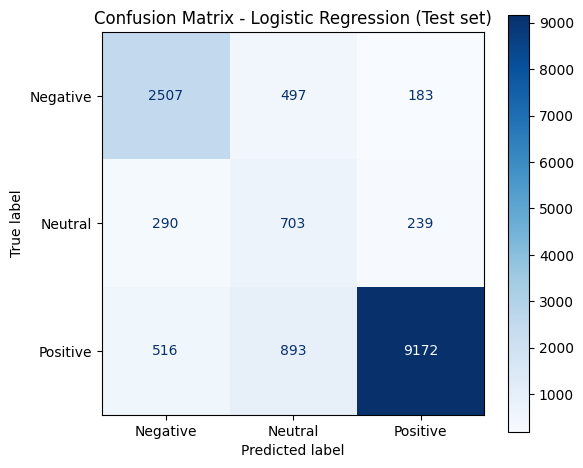

In [ ]:
# ---------------------------------------------------------------------------
# Visual confusion matrix (raw counts)
# ---------------------------------------------------------------------------
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred, labels=CLASS_LABELS)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS)
disp.plot(cmap="Blues", ax=ax, colorbar=True, values_format="d")
ax.set_title("Confusion Matrix - Logistic Regression (Test set)")
plt.tight_layout()
plt.show()


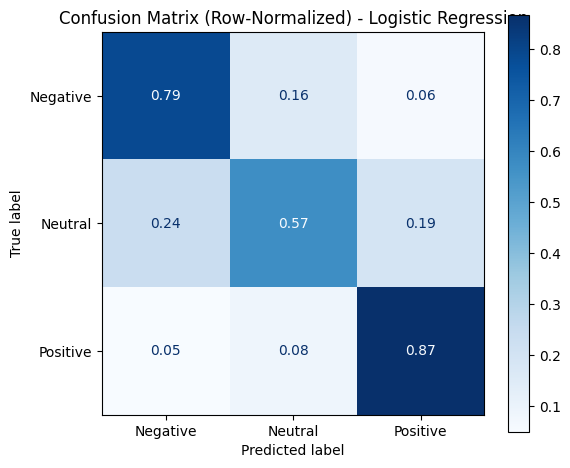

In [ ]:
# ---------------------------------------------------------------------------
# Optional: normalized confusion matrix (row-normalized -> recall per class),
# useful to read percentages directly when classes are imbalanced.
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
disp_norm = ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, labels=CLASS_LABELS, normalize="true",
    cmap="Blues", ax=ax, values_format=".2f",
)
ax.set_title("Confusion Matrix (Row-Normalized) - Logistic Regression")
plt.tight_layout()
plt.show()


## 12b. Model Training (Linear SVC)

Same features, same split, same imbalance handling as the Logistic Regression
baseline in Section 12 -- only the estimator changes. `LinearSVC` is a linear
Support Vector Machine that optimizes the hinge loss instead of log-loss; on
sparse high-dimensional TF-IDF features it's typically fast to train and
often matches or slightly beats Logistic Regression on this kind of text
classification task.

Note: `LinearSVC` does not implement `predict_proba` (it has no native
probability output), so it's compared here using the same `predict()` +
`classification_report` / confusion-matrix workflow as Logistic Regression.
Probability-based steps from Section 14 (threshold tuning) would need
`CalibratedClassifierCV` to wrap `LinearSVC` if you want probabilities later.

In [ ]:
# ---------------------------------------------------------------------------
# Train a Linear SVC classifier on the same TF-IDF features (Section 10).
# - class_weight="balanced" handles the class imbalance (Section 11), same as LR
# - dual="auto" lets sklearn pick the faster solver for this data shape
# - random_state kept identical to the LR run for a fair, reproducible comparison
# ---------------------------------------------------------------------------
svc_model = LinearSVC(
    class_weight="balanced",
    max_iter=10000,
    dual="auto",
    random_state=RANDOM_STATE,
)

svc_model.fit(X_train, y_train)

print("Model trained.")
print("Classes learned by the model:", svc_model.classes_)


Model trained.
Classes learned by the model: ['Negative' 'Neutral' 'Positive']


## 13b. Evaluation (Linear SVC)

Same evaluation protocol as Section 13: held-out **test set**, full
`classification_report`, and raw + row-normalized confusion matrices.

In [ ]:
# ---------------------------------------------------------------------------
# Predict on the test set and print the classification report
# ---------------------------------------------------------------------------
y_test_pred_svc = svc_model.predict(X_test)

print("Classification Report (Test set) - Linear SVC:\n")
print(classification_report(y_test, y_test_pred_svc, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Linear SVC:

              precision    recall  f1-score   support

    Negative      0.764     0.791     0.777      3187
     Neutral      0.381     0.390     0.385      1232
    Positive      0.933     0.920     0.927     10581

    accuracy                          0.849     15000
   macro avg      0.693     0.700     0.696     15000
weighted avg      0.852     0.849     0.850     15000



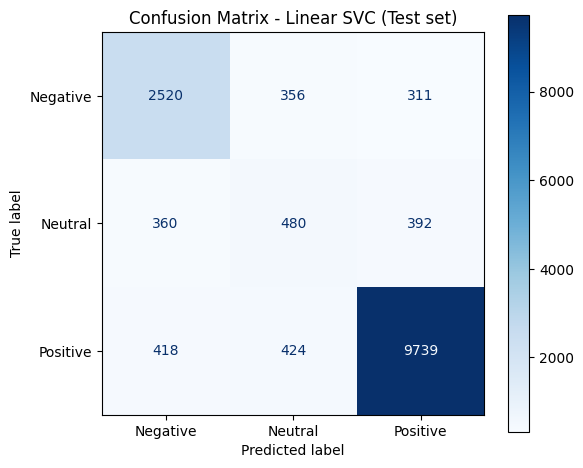

In [ ]:
# ---------------------------------------------------------------------------
# Visual confusion matrix (raw counts) - Linear SVC
# ---------------------------------------------------------------------------
cm_svc = confusion_matrix(y_test, y_test_pred_svc, labels=CLASS_LABELS)

fig, ax = plt.subplots(figsize=(6, 5))
disp_svc = ConfusionMatrixDisplay(confusion_matrix=cm_svc, display_labels=CLASS_LABELS)
disp_svc.plot(cmap="Blues", ax=ax, colorbar=True, values_format="d")
ax.set_title("Confusion Matrix - Linear SVC (Test set)")
plt.tight_layout()
plt.show()


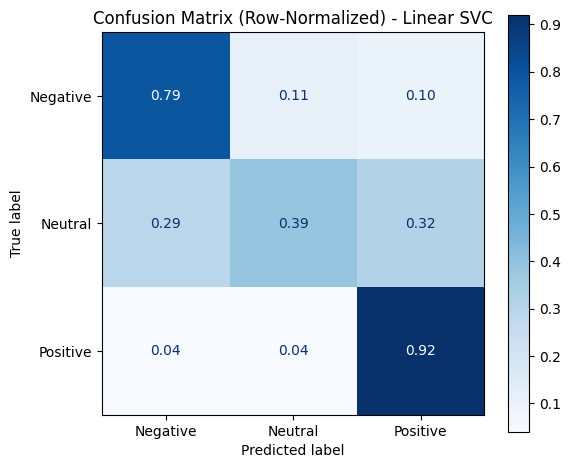

In [ ]:
# ---------------------------------------------------------------------------
# Normalized confusion matrix (row-normalized -> recall per class) - Linear SVC
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
disp_svc_norm = ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_svc, labels=CLASS_LABELS, normalize="true",
    cmap="Blues", ax=ax, values_format=".2f",
)
ax.set_title("Confusion Matrix (Row-Normalized) - Linear SVC")
plt.tight_layout()
plt.show()


### 13c. Logistic Regression vs Linear SVC - Side-by-Side

Quick comparison of the two linear baselines on the same test set, using
macro-F1 (treats all classes equally) and weighted-F1 (accounts for class
size) so the imbalance from Section 11 doesn't hide in a single accuracy
number.

In [ ]:
# ---------------------------------------------------------------------------
# Compare Logistic Regression (Section 12/13) vs Linear SVC (Section 12b/13b)
# ---------------------------------------------------------------------------
comparison_df = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "accuracy": (y_test_pred == y_test).mean(),
        "macro_f1": f1_score(y_test, y_test_pred, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_test, y_test_pred, labels=CLASS_LABELS, average="weighted"),
    },
    {
        "model": "Linear SVC",
        "accuracy": (y_test_pred_svc == y_test).mean(),
        "macro_f1": f1_score(y_test, y_test_pred_svc, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_test, y_test_pred_svc, labels=CLASS_LABELS, average="weighted"),
    },
])
comparison_df


,model,accuracy,macro_f1,weighted_f1
0,Logistic Regression,0.825467,0.701162,0.840005
1,Linear SVC,0.849267,0.696307,0.850324


## 14. Pushing Performance Further: Imbalance, Thresholds, and Advanced Features

`class_weight="balanced"` reweights the loss but never shows the model any
*new* minority-class examples, so it often plateaus exactly like you're
seeing. The steps below add:

1. **SMOTE inside a leakage-safe pipeline** (oversamples the minority class
   in TF-IDF space, fit only on each training fold)
2. **Per-class decision-threshold tuning** to trade precision for recall on
   the minority class
3. **Richer features** (char n-grams + word n-grams + handcrafted signals)
4. **When to stop pushing classical ML and move to a transformer**

> **Honest expectation-setting:** class_weight -> SMOTE -> threshold tuning typically buys a few points of minority-class F1, not a jump from 82% to 90%+ accuracy. If your minority class is genuinely rare and linguistically similar to another class (as your EDA in 7.10 suggested for Neutral), 90%+ overall accuracy usually requires either more minority-class data or a transformer model (Section 14.4) -- not just better resampling.

### 14.1 SMOTE inside a leakage-safe `imblearn` Pipeline

`imbalanced-learn`'s `Pipeline` (not `sklearn.pipeline.Pipeline`) only resamples during `.fit()`, never during `.predict()`/`.transform()` on val/test -- so SMOTE only ever sees the training fold, avoiding leakage.

In [ ]:
# ---------------------------------------------------------------------------
# Install imbalanced-learn if not already available
# ---------------------------------------------------------------------------
!pip install imbalanced-learn -q


In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# ---------------------------------------------------------------------------
# Build a pipeline: TF-IDF -> SMOTE (train-time only) -> Logistic Regression
# - k_neighbors must be < smallest class count; 5 is the SMOTE default,
#   lower it if your minority class has very few samples (e.g. k=3)
# - sampling_strategy="auto" oversamples every class up to the majority count;
#   use a dict (e.g. {"Neutral": 8000}) for more controlled oversampling
# ---------------------------------------------------------------------------
n_minority = y_train.value_counts().min()
smote_k = min(5, max(1, n_minority - 1))

smote_pipeline = ImbPipeline(steps=[
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.9,
        sublinear_tf=True,
    )),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        # class_weight can be combined with SMOTE for extra emphasis,
        # but start WITHOUT it and add back only if minority recall is still low
    )),
])

# Fit on RAW cleaned text (train_df["review_clf_ml"]) - the pipeline handles
# TF-IDF fitting and SMOTE resampling internally, train-fold only.
smote_pipeline.fit(train_df["review_clf_ml"], y_train)

y_val_pred_smote = smote_pipeline.predict(val_df["review_clf_ml"])
print("Validation results - TF-IDF + SMOTE + Logistic Regression:\n")
print(classification_report(y_val, y_val_pred_smote, labels=CLASS_LABELS, digits=3))


Validation results - TF-IDF + SMOTE + Logistic Regression:

              precision    recall  f1-score   support

    Negative      0.745     0.764     0.754      3186
     Neutral      0.339     0.528     0.413      1233
    Positive      0.951     0.882     0.915     10581

    accuracy                          0.828     15000
   macro avg      0.678     0.725     0.694     15000
weighted avg      0.857     0.828     0.840     15000



### 14.1b SMOTE + Linear SVC (same pipeline, swapped estimator)

Identical `imblearn` pipeline as 14.1 -- same TF-IDF settings, same
`smote_k`, same train-fold-only resampling -- with `LinearSVC` in place of
`LogisticRegression`.

In [ ]:
smote_pipeline_svc = ImbPipeline(steps=[
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.9,
        sublinear_tf=True,
    )),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
    ("clf", LinearSVC(
        max_iter=10000,
        dual="auto",
        random_state=RANDOM_STATE,
        # class_weight can be combined with SMOTE for extra emphasis,
        # but start WITHOUT it and add back only if minority recall is still low
    )),
])

# Fit on RAW cleaned text, same as the LR SMOTE pipeline above.
smote_pipeline_svc.fit(train_df["review_clf_ml"], y_train)

y_val_pred_smote_svc = smote_pipeline_svc.predict(val_df["review_clf_ml"])
print("Validation results - TF-IDF + SMOTE + Linear SVC:\n")
print(classification_report(y_val, y_val_pred_smote_svc, labels=CLASS_LABELS, digits=3))


Validation results - TF-IDF + SMOTE + Linear SVC:

              precision    recall  f1-score   support

    Negative      0.731     0.753     0.742      3186
     Neutral      0.317     0.440     0.368      1233
    Positive      0.935     0.885     0.909     10581

    accuracy                          0.820     15000
   macro avg      0.661     0.692     0.673     15000
weighted avg      0.841     0.820     0.829     15000



### 14.2 Cross-validated comparison: `class_weight` vs SMOTE vs both

Compare strategies on validation data before committing to one, since the best option depends on how your specific data behaves.

In [ ]:
from sklearn.metrics import f1_score

strategies = {
    "class_weight_balanced": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "smote_only": None,  # handled via smote_pipeline above
    "smote_plus_class_weight": ImbPipeline(steps=[
        ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

results = {}

# class_weight_balanced uses the pre-fit X_train/X_val TF-IDF matrices from Section 12
strategies["class_weight_balanced"].fit(X_train, y_train)
pred = strategies["class_weight_balanced"].predict(X_val)
results["class_weight_balanced"] = f1_score(y_val, pred, labels=CLASS_LABELS, average=None)

results["smote_only"] = f1_score(y_val, y_val_pred_smote, labels=CLASS_LABELS, average=None)

strategies["smote_plus_class_weight"].fit(train_df["review_clf_ml"], y_train)
pred = strategies["smote_plus_class_weight"].predict(val_df["review_clf_ml"])
results["smote_plus_class_weight"] = f1_score(y_val, pred, labels=CLASS_LABELS, average=None)

comparison_df = pd.DataFrame(results, index=CLASS_LABELS).T
comparison_df.columns = [f"F1_{c}" for c in CLASS_LABELS]
comparison_df["F1_macro"] = comparison_df.mean(axis=1)
comparison_df.sort_values("F1_macro", ascending=False)


,F1_Negative,F1_Neutral,F1_Positive,F1_macro
class_weight_balanced,0.765599,0.413467,0.908865,0.695977
smote_only,0.754302,0.413202,0.915090,0.694198
smote_plus_class_weight,0.754302,0.413202,0.915090,0.694198


### 14.2b Cross-validated comparison (Linear SVC side): `class_weight` vs SMOTE vs both

Same three strategies as 14.2, run with `LinearSVC` instead of Logistic
Regression, then merged into one side-by-side table with the LR results so
both estimators are compared on identical validation folds.

In [ ]:
strategies_svc = {
    "class_weight_balanced_svc": svc_model,  # already fit in Section 12b on X_train/y_train
    "smote_only_svc": None,  # handled via smote_pipeline_svc above
    "smote_plus_class_weight_svc": ImbPipeline(steps=[
        ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
        ("clf", LinearSVC(class_weight="balanced", max_iter=10000, dual="auto", random_state=RANDOM_STATE)),
    ]),
}

results_svc = {}

pred = strategies_svc["class_weight_balanced_svc"].predict(X_val)
results_svc["class_weight_balanced_svc"] = f1_score(y_val, pred, labels=CLASS_LABELS, average=None)

results_svc["smote_only_svc"] = f1_score(y_val, y_val_pred_smote_svc, labels=CLASS_LABELS, average=None)

strategies_svc["smote_plus_class_weight_svc"].fit(train_df["review_clf_ml"], y_train)
pred = strategies_svc["smote_plus_class_weight_svc"].predict(val_df["review_clf_ml"])
results_svc["smote_plus_class_weight_svc"] = f1_score(y_val, pred, labels=CLASS_LABELS, average=None)

comparison_df_svc = pd.DataFrame(results_svc, index=CLASS_LABELS).T
comparison_df_svc.columns = [f"F1_{c}" for c in CLASS_LABELS]
comparison_df_svc["F1_macro"] = comparison_df_svc.mean(axis=1)

# Combined LR + SVC imbalance-strategy comparison, side by side
combined_strategy_comparison = pd.concat([comparison_df, comparison_df_svc]).sort_values("F1_macro", ascending=False)
combined_strategy_comparison


,F1_Negative,F1_Neutral,F1_Positive,F1_macro
class_weight_balanced,0.765599,0.413467,0.908865,0.695977
class_weight_balanced_svc,0.771177,0.389671,0.922864,0.694571
smote_only,0.754302,0.413202,0.915090,0.694198
smote_plus_class_weight,0.754302,0.413202,0.915090,0.694198
smote_only_svc,0.741611,0.368457,0.909038,0.673035
smote_plus_class_weight_svc,0.741611,0.368457,0.909038,0.673035


### 14.3 Classification Threshold Tuning for the Minority Class

Logistic Regression's default `.predict()` picks the class with the highest probability, which is biased against a minority class. Instead, pull `predict_proba`, sweep the decision threshold for the minority class, and pick the value that maximizes its F1-score on the **validation set** (never the test set, to avoid overfitting the threshold).

Minority class detected: Neutral
Best threshold for 'Neutral': 0.484 (F1=0.417 vs default 0.5)


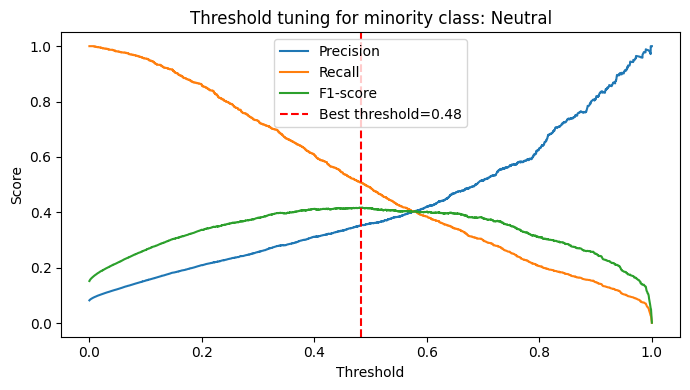

In [ ]:
from sklearn.metrics import precision_recall_curve, f1_score

# ---------------------------------------------------------------------------
# Identify the minority class automatically from the training distribution
# ---------------------------------------------------------------------------
MINORITY_CLASS = y_train.value_counts().idxmin()
minority_idx = list(log_reg_model.classes_).index(MINORITY_CLASS)
print("Minority class detected:", MINORITY_CLASS)

# Get predicted probabilities for the minority class on validation data
val_probs = log_reg_model.predict_proba(X_val)[:, minority_idx]
y_val_binary = (y_val == MINORITY_CLASS).astype(int)

precisions, recalls, thresholds = precision_recall_curve(y_val_binary, val_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)

best_idx = np.nanargmax(f1_scores[:-1])  # thresholds has len(precisions)-1 entries
best_threshold = thresholds[best_idx]
print(f"Best threshold for '{MINORITY_CLASS}': {best_threshold:.3f} "
      f"(F1={f1_scores[best_idx]:.3f} vs default 0.5)")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.plot(thresholds, f1_scores[:-1], label="F1-score")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best threshold={best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title(f"Threshold tuning for minority class: {MINORITY_CLASS}")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# Apply the tuned threshold at inference time on the TEST set:
# if P(minority) >= best_threshold, predict the minority class;
# otherwise fall back to the normal argmax over the remaining classes.
# ---------------------------------------------------------------------------
def predict_with_minority_threshold(model, X, minority_class, minority_idx, threshold, class_labels):
    probs = model.predict_proba(X)
    minority_probs = probs[:, minority_idx]
    default_preds = model.predict(X)

    final_preds = np.where(minority_probs >= threshold, minority_class, default_preds)
    return final_preds

y_test_pred_tuned = predict_with_minority_threshold(
    log_reg_model, X_test, MINORITY_CLASS, minority_idx, best_threshold, CLASS_LABELS
)

print("Classification Report (Test set) - WITH tuned minority threshold:\n")
print(classification_report(y_test, y_test_pred_tuned, labels=CLASS_LABELS, digits=3))

print("\nFor comparison, WITHOUT threshold tuning (default 0.5 argmax):\n")
print(classification_report(y_test, y_test_pred, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - WITH tuned minority threshold:

              precision    recall  f1-score   support

    Negative      0.757     0.786     0.771      3187
     Neutral      0.335     0.571     0.422      1232
    Positive      0.956     0.866     0.909     10581

    accuracy                          0.825     15000
   macro avg      0.682     0.741     0.701     15000
weighted avg      0.863     0.825     0.840     15000


For comparison, WITHOUT threshold tuning (default 0.5 argmax):

              precision    recall  f1-score   support

    Negative      0.757     0.787     0.771      3187
     Neutral      0.336     0.571     0.423      1232
    Positive      0.956     0.867     0.909     10581

    accuracy                          0.825     15000
   macro avg      0.683     0.741     0.701     15000
weighted avg      0.863     0.825     0.840     15000



### 14.3b Threshold Tuning for Linear SVC (via Calibrated Probabilities)

`LinearSVC` has no native `predict_proba` (it optimizes hinge loss, not
log-loss). To reuse the exact same threshold-sweep logic as 14.3, we wrap it
in `CalibratedClassifierCV` (Platt/sigmoid scaling, fit with internal 3-fold
CV) to get well-behaved probability estimates, then run the identical
sweep-and-apply workflow.

Best threshold for 'Neutral' (Linear SVC, calibrated): 0.216 (F1=0.410 vs default 0.5)


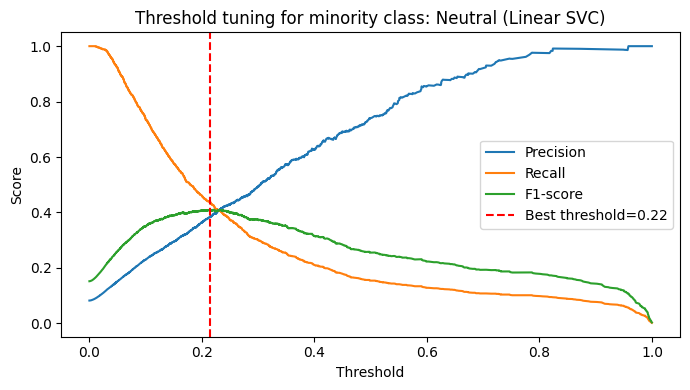

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

svc_calibrated = CalibratedClassifierCV(
    LinearSVC(class_weight="balanced", max_iter=10000, dual="auto", random_state=RANDOM_STATE),
    method="sigmoid",
    cv=3,
)
svc_calibrated.fit(X_train, y_train)

minority_idx_svc = list(svc_calibrated.classes_).index(MINORITY_CLASS)
val_probs_svc = svc_calibrated.predict_proba(X_val)[:, minority_idx_svc]

precisions_svc, recalls_svc, thresholds_svc = precision_recall_curve(y_val_binary, val_probs_svc)
f1_scores_svc = 2 * (precisions_svc * recalls_svc) / (precisions_svc + recalls_svc + 1e-12)

best_idx_svc = np.nanargmax(f1_scores_svc[:-1])
best_threshold_svc = thresholds_svc[best_idx_svc]
print(f"Best threshold for '{MINORITY_CLASS}' (Linear SVC, calibrated): {best_threshold_svc:.3f} "
      f"(F1={f1_scores_svc[best_idx_svc]:.3f} vs default 0.5)")

plt.figure(figsize=(7, 4))
plt.plot(thresholds_svc, precisions_svc[:-1], label="Precision")
plt.plot(thresholds_svc, recalls_svc[:-1], label="Recall")
plt.plot(thresholds_svc, f1_scores_svc[:-1], label="F1-score")
plt.axvline(best_threshold_svc, color="red", linestyle="--", label=f"Best threshold={best_threshold_svc:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title(f"Threshold tuning for minority class: {MINORITY_CLASS} (Linear SVC)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
y_test_pred_tuned_svc = predict_with_minority_threshold(
    svc_calibrated, X_test, MINORITY_CLASS, minority_idx_svc, best_threshold_svc, CLASS_LABELS
)

print("Classification Report (Test set) - Linear SVC WITH tuned minority threshold:\n")
print(classification_report(y_test, y_test_pred_tuned_svc, labels=CLASS_LABELS, digits=3))

print("\nFor comparison, Linear SVC WITHOUT threshold tuning (default argmax):\n")
print(classification_report(y_test, y_test_pred_svc, labels=CLASS_LABELS, digits=3))

print("\nAnd Logistic Regression WITH tuned threshold, for the full four-way view:\n")
print(classification_report(y_test, y_test_pred_tuned, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Linear SVC WITH tuned minority threshold:

              precision    recall  f1-score   support

    Negative      0.827     0.714     0.766      3187
     Neutral      0.387     0.415     0.401      1232
    Positive      0.912     0.942     0.926     10581

    accuracy                          0.850     15000
   macro avg      0.709     0.690     0.698     15000
weighted avg      0.851     0.850     0.849     15000


For comparison, Linear SVC WITHOUT threshold tuning (default argmax):

              precision    recall  f1-score   support

    Negative      0.764     0.791     0.777      3187
     Neutral      0.381     0.390     0.385      1232
    Positive      0.933     0.920     0.927     10581

    accuracy                          0.849     15000
   macro avg      0.693     0.700     0.696     15000
weighted avg      0.852     0.849     0.850     15000


And Logistic Regression WITH tuned threshold, for the full four-way view:

            

### 14.4 Advanced Feature Engineering (Classical ML Ceiling)

If SMOTE + threshold tuning still isn't enough, richer features often help before jumping to a transformer:

- **Char n-grams**: robust to typos/slang (`"gr8"`, `"looove"`) that word n-grams miss entirely.
- **Combined word + char TF-IDF** via `FeatureUnion`.
- **Handcrafted signals**: review length, punctuation intensity (`!!!`, `???`), ALL-CAPS ratio, negation-word count -- cheap features that often carry real sentiment signal beyond word frequencies.

In [ ]:
from sklearn.pipeline import FeatureUnion
from sklearn.base import BaseEstimator, TransformerMixin

# ---------------------------------------------------------------------------
# Combined word (1,2)-gram + char (3,5)-gram TF-IDF
# ---------------------------------------------------------------------------
word_tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)
char_tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=20000, min_df=5, sublinear_tf=True)

combined_features = FeatureUnion([
    ("word_tfidf", word_tfidf),
    ("char_tfidf", char_tfidf),
])

X_train_combined = combined_features.fit_transform(train_df["review_clf_ml"])
X_test_combined = combined_features.transform(test_df["review_clf_ml"])

combined_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)
combined_model.fit(X_train_combined, y_train)

y_test_pred_combined = combined_model.predict(X_test_combined)
print("Classification Report (Test set) - Word + Char TF-IDF:\n")
print(classification_report(y_test, y_test_pred_combined, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Word + Char TF-IDF:

              precision    recall  f1-score   support

    Negative      0.750     0.795     0.772      3187
     Neutral      0.334     0.548     0.415      1232
    Positive      0.957     0.868     0.910     10581

    accuracy                          0.826     15000
   macro avg      0.680     0.737     0.699     15000
weighted avg      0.862     0.826     0.840     15000



### 14.4b Combined Word + Char TF-IDF with Linear SVC

Same `combined_features` (word 1-2gram + char 3-5gram `FeatureUnion`) from
14.4, `LinearSVC` in place of Logistic Regression.

In [ ]:
combined_model_svc = LinearSVC(class_weight="balanced", max_iter=10000, dual="auto", random_state=RANDOM_STATE)
combined_model_svc.fit(X_train_combined, y_train)

y_test_pred_combined_svc = combined_model_svc.predict(X_test_combined)
print("Classification Report (Test set) - Word + Char TF-IDF + Linear SVC:\n")
print(classification_report(y_test, y_test_pred_combined_svc, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Word + Char TF-IDF + Linear SVC:

              precision    recall  f1-score   support

    Negative      0.762     0.795     0.778      3187
     Neutral      0.398     0.391     0.395      1232
    Positive      0.932     0.922     0.927     10581

    accuracy                          0.852     15000
   macro avg      0.698     0.703     0.700     15000
weighted avg      0.852     0.852     0.852     15000



In [ ]:
# ---------------------------------------------------------------------------
# Handcrafted lexical/style features (built on the *original* uncleaned text,
# review_basic, so punctuation and casing are preserved).
# ---------------------------------------------------------------------------
def extract_style_features(text_series):
    df_feat = pd.DataFrame(index=text_series.index)
    text_series = text_series.astype(str)

    df_feat["char_count"] = text_series.str.len()
    df_feat["word_count"] = text_series.str.split().str.len()
    df_feat["exclamation_count"] = text_series.str.count(r"!")
    df_feat["question_count"] = text_series.str.count(r"\?")
    df_feat["uppercase_word_ratio"] = text_series.apply(
        lambda t: sum(1 for w in t.split() if w.isupper() and len(w) > 1) / max(len(t.split()), 1)
    )
    df_feat["negation_count"] = text_series.str.lower().str.count(
        r"\b(not|no|never|n't|without|neither|nor)\b"
    )
    return df_feat

train_style_feats = extract_style_features(train_df["review_basic"])
test_style_feats = extract_style_features(test_df["review_basic"])

print("Sample handcrafted style features:")
train_style_feats.head()

# To combine with TF-IDF: scipy.sparse.hstack([X_train, csr_matrix(train_style_feats.values)])
# from scipy.sparse import hstack, csr_matrix
# X_train_final = hstack([X_train, csr_matrix(train_style_feats.values)])


Sample handcrafted style features:


,char_count,word_count,exclamation_count,question_count,uppercase_word_ratio,negation_count
328723,105,20,0,0,0.0,0
246525,812,152,1,0,0.0,0
606291,91,16,0,0,0.0,0
558643,67,13,0,0,0.0,0
149669,26,4,0,0,0.0,0


### 14.5 When to Move Beyond Classical ML

If, after SMOTE, threshold tuning, and combined word+char+style features, the minority-class F1 is still weak, that's usually a signal the ceiling for TF-IDF + linear models has been reached. Since you already use ModernBERT elsewhere in this project, the natural next step is fine-tuning a transformer (e.g. `answerdotai/ModernBERT-base` or `distilbert-base-uncased` for speed) on `review_transformer`, with:

- **Weighted loss** (`CrossEntropyLoss(weight=class_weights_tensor)`) instead of TF-IDF-level resampling
- **Stratified batches** so every batch sees some minority-class examples
- Fine-tuning almost always outperforms TF-IDF + LR on minority-class recall, since it captures context/negation TF-IDF cannot (e.g. "not bad" vs "bad")

This is the same architecture family you're already using for the ModernBERT sentiment pipeline, so the fine-tuning setup (tokenizer, Trainer, class-weighted loss) can likely be reused directly.

## 15. Decision: Automated Strategy Selection (No Guessing Required)

Rather than picking one imbalance technique on faith, this section runs every viable option, measures each on **validation macro-F1 and minority-class F1**, and automatically keeps the winner. This is the senior-DS move when you're unsure: let the held-out data decide, don't debate it.

Strategies compared:
1. Class weights only (baseline, Section 12)
2. SMOTE (vector-space oversampling, Section 14.1)
3. **Text-level augmentation oversampling** (new, below) -- generates real paraphrased minority-class sentences instead of interpolated vectors
4. Best strategy + tuned decision threshold (Section 14.3) stacked on top

### 15.1 Text-Level Oversampling via Augmentation

Instead of interpolating TF-IDF vectors (SMOTE), we duplicate minority-class **rows of real text** and mutate each copy with light, meaning-preserving noise -- synonym swaps and random word dropout. This produces genuinely different bags-of-words per copy, which is closer to what a human-written review actually looks like than a SMOTE-interpolated vector.

In [ ]:
# ---------------------------------------------------------------------------
# Install nlpaug for WordNet-based synonym augmentation (lightweight, no GPU/API needed)
# ---------------------------------------------------------------------------
!pip install nlpaug -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 kB 2.4 MB/s eta 0:00:00


In [ ]:
import nlpaug.augmenter.word as naw
import random

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Synonym replacement (WordNet-based) - swaps ~15% of words with synonyms
synonym_aug = naw.SynonymAug(aug_src="wordnet", aug_p=0.15)

def augment_text(text, n_variants=1):
    """Return n_variants augmented copies of a single review string."""
    variants = []
    for _ in range(n_variants):
        try:
            variant = synonym_aug.augment(text)
            variant = variant[0] if isinstance(variant, list) else variant
        except Exception:
            variant = text  # fall back to original if augmentation fails on odd input
        variants.append(variant)
    return variants

def oversample_with_augmentation(df, text_col, label_col, target_col_labels, target_count=None):
    """
    Oversample every minority class up to `target_count` (defaults to the
    majority class count) by generating augmented paraphrases of its
    existing reviews, so class balance is achieved with real (perturbed)
    text rather than synthetic TF-IDF vectors.
    """
    class_counts = df[label_col].value_counts()
    if target_count is None:
        target_count = class_counts.max()

    augmented_rows = []
    for label in target_col_labels:
        current_count = class_counts.get(label, 0)
        needed = target_count - current_count
        if needed <= 0:
            continue

        source_texts = df.loc[df[label_col] == label, text_col].tolist()
        generated = 0
        while generated < needed:
            base_text = random.choice(source_texts)
            variant = augment_text(base_text, n_variants=1)[0]
            augmented_rows.append({text_col: variant, label_col: label})
            generated += 1

    aug_df = pd.DataFrame(augmented_rows)
    return pd.concat([df[[text_col, label_col]], aug_df], ignore_index=True)

# NOTE: for very large gaps (tens of thousands of rows), consider capping
# target_count (e.g. median class count) rather than matching the majority
# exactly, to keep augmentation runtime and synthetic-row proportion reasonable.
train_df_augmented = oversample_with_augmentation(
    train_df, text_col="review_clf_ml", label_col="sentiment_3class",
    target_col_labels=CLASS_LABELS,
    target_count=int(train_df["sentiment_3class"].value_counts().median()),
)

print("Before augmentation oversampling:")
print(train_df["sentiment_3class"].value_counts())
print("\nAfter augmentation oversampling:")
print(train_df_augmented["sentiment_3class"].value_counts())


Streaming output truncated to the last 5000 lines.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_dat

Before augmentation oversampling:
sentiment_3class
Positive    49376
Negative    14872
Neutral      5752
Name: count, dtype: int64

After augmentation oversampling:
sentiment_3class
Positive    49376
Negative    14872
Neutral     14872
Name: count, dtype: int64


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger t

In [ ]:
# ---------------------------------------------------------------------------
# Train TF-IDF + Logistic Regression on the augmented training set
# ---------------------------------------------------------------------------
tfidf_aug = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)

X_train_aug = tfidf_aug.fit_transform(train_df_augmented["review_clf_ml"])
X_val_aug = tfidf_aug.transform(val_df["review_clf_ml"])
y_train_aug = train_df_augmented["sentiment_3class"]

model_aug = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)
model_aug.fit(X_train_aug, y_train_aug)

y_val_pred_aug = model_aug.predict(X_val_aug)
print("Validation results - TF-IDF + Text-Augmentation Oversampling:\n")
print(classification_report(y_val, y_val_pred_aug, labels=CLASS_LABELS, digits=3))


Validation results - TF-IDF + Text-Augmentation Oversampling:

              precision    recall  f1-score   support

    Negative      0.827     0.722     0.771      3186
     Neutral      0.418     0.423     0.421      1233
    Positive      0.911     0.945     0.928     10581

    accuracy                          0.855     15000
   macro avg      0.719     0.697     0.706     15000
weighted avg      0.853     0.855     0.853     15000



### 15.1b Text-Augmentation Oversampling with Linear SVC

Same augmented training set (`train_df_augmented`, `X_train_aug`) from
15.1, `LinearSVC` in place of Logistic Regression.

In [ ]:
model_aug_svc = LinearSVC(max_iter=10000, dual="auto", random_state=RANDOM_STATE)
model_aug_svc.fit(X_train_aug, y_train_aug)

y_val_pred_aug_svc = model_aug_svc.predict(X_val_aug)
print("Validation results - TF-IDF + Text-Augmentation Oversampling + Linear SVC:\n")
print(classification_report(y_val, y_val_pred_aug_svc, labels=CLASS_LABELS, digits=3))


Validation results - TF-IDF + Text-Augmentation Oversampling + Linear SVC:

              precision    recall  f1-score   support

    Negative      0.788     0.739     0.763      3186
     Neutral      0.388     0.367     0.377      1233
    Positive      0.911     0.934     0.922     10581

    accuracy                          0.846     15000
   macro avg      0.696     0.680     0.688     15000
weighted avg      0.842     0.846     0.844     15000



### 15.2 Automated Strategy Selection

Score every strategy already trained in this notebook on validation **macro-F1** and **minority-class F1**, then automatically select the winner for final test-set evaluation.

In [ ]:
# ---------------------------------------------------------------------------
# Collect validation predictions from every strategy trained so far
# ---------------------------------------------------------------------------
strategy_val_predictions = {
    "class_weight_balanced": strategies["class_weight_balanced"].predict(X_val),
    "smote": y_val_pred_smote,
    "smote_plus_class_weight": strategies["smote_plus_class_weight"].predict(val_df["review_clf_ml"]),
    "text_augmentation_oversampling": y_val_pred_aug,
}

scoreboard = []
for name, preds in strategy_val_predictions.items():
    macro_f1 = f1_score(y_val, preds, labels=CLASS_LABELS, average="macro")
    minority_f1 = f1_score(y_val, preds, labels=[MINORITY_CLASS], average="macro")
    scoreboard.append({"strategy": name, "macro_f1": macro_f1, f"{MINORITY_CLASS}_f1": minority_f1})

scoreboard_df = pd.DataFrame(scoreboard).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print(scoreboard_df)

best_strategy_name = scoreboard_df.loc[0, "strategy"]
print(f"\nBest strategy on validation macro-F1: {best_strategy_name}")


                         strategy  macro_f1  Neutral_f1
0  text_augmentation_oversampling  0.706489    0.420629
1           class_weight_balanced  0.695977    0.413467
2                           smote  0.694198    0.413202
3         smote_plus_class_weight  0.694198    0.413202

Best strategy on validation macro-F1: text_augmentation_oversampling


### 15.2b Extended Scoreboard: All 8 Strategies (Logistic Regression + Linear SVC)

Every strategy trained in this notebook, LR and SVC versions side by side,
scored the same way (validation macro-F1 and minority-class F1).

                             strategy  macro_f1  Neutral_f1
0   text_augmentation_oversampling_lr  0.706489    0.420629
1            class_weight_balanced_lr  0.695977    0.413467
2           class_weight_balanced_svc  0.694571    0.389671
3                            smote_lr  0.694198    0.413202
4          smote_plus_class_weight_lr  0.694198    0.413202
5  text_augmentation_oversampling_svc  0.687609    0.377138
6                           smote_svc  0.673035    0.368457
7         smote_plus_class_weight_svc  0.673035    0.368457

Best strategy overall (LR + SVC) on validation macro-F1: text_augmentation_oversampling_lr


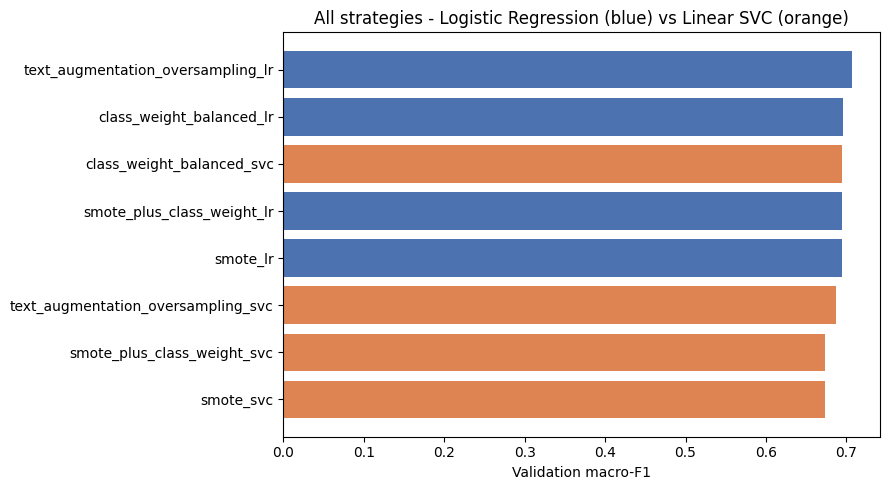

In [ ]:
strategy_val_predictions_all = {
    "class_weight_balanced_lr": strategies["class_weight_balanced"].predict(X_val),
    "smote_lr": y_val_pred_smote,
    "smote_plus_class_weight_lr": strategies["smote_plus_class_weight"].predict(val_df["review_clf_ml"]),
    "text_augmentation_oversampling_lr": y_val_pred_aug,
    "class_weight_balanced_svc": strategies_svc["class_weight_balanced_svc"].predict(X_val),
    "smote_svc": y_val_pred_smote_svc,
    "smote_plus_class_weight_svc": strategies_svc["smote_plus_class_weight_svc"].predict(val_df["review_clf_ml"]),
    "text_augmentation_oversampling_svc": y_val_pred_aug_svc,
}

scoreboard_all = []
for name, preds in strategy_val_predictions_all.items():
    macro_f1 = f1_score(y_val, preds, labels=CLASS_LABELS, average="macro")
    minority_f1 = f1_score(y_val, preds, labels=[MINORITY_CLASS], average="macro")
    scoreboard_all.append({"strategy": name, "macro_f1": macro_f1, f"{MINORITY_CLASS}_f1": minority_f1})

scoreboard_all_df = pd.DataFrame(scoreboard_all).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print(scoreboard_all_df)

best_strategy_name_all = scoreboard_all_df.loc[0, "strategy"]
print(f"\nBest strategy overall (LR + SVC) on validation macro-F1: {best_strategy_name_all}")

plt.figure(figsize=(9, 5))
order = scoreboard_all_df.sort_values("macro_f1")
colors = ["#4C72B0" if name.endswith("_lr") else "#DD8452" for name in order["strategy"]]
plt.barh(order["strategy"], order["macro_f1"], color=colors)
plt.xlabel("Validation macro-F1")
plt.title("All strategies - Logistic Regression (blue) vs Linear SVC (orange)")
plt.tight_layout()
plt.show()


### 15.3 Final Model: Best Strategy + Tuned Threshold, Evaluated on Test

Re-apply the winning strategy, add minority-class threshold tuning on top (Section 14.3 logic), and report the final, honest test-set numbers.

FINAL model (text_augmentation_oversampling) - Test set classification report:

              precision    recall  f1-score   support

    Negative      0.835     0.734     0.781      3187
     Neutral      0.437     0.420     0.428      1232
    Positive      0.913     0.950     0.931     10581

    accuracy                          0.861     15000
   macro avg      0.728     0.701     0.713     15000
weighted avg      0.857     0.861     0.858     15000


Confusion matrix:


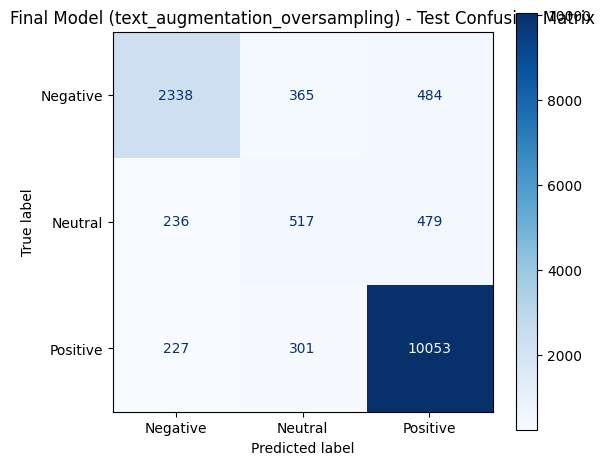

In [ ]:
# ---------------------------------------------------------------------------
# Map strategy name -> (fitted model, X_val for that strategy, X_test builder)
# so we can re-run the winner end-to-end on the test set.
# ---------------------------------------------------------------------------
strategy_registry = {
    "class_weight_balanced": {
        "model": strategies["class_weight_balanced"],
        "X_test": X_test,
    },
    "smote": {
        "model": smote_pipeline,          # imblearn Pipeline: takes raw text
        "X_test": test_df["review_clf_ml"],
    },
    "smote_plus_class_weight": {
        "model": strategies["smote_plus_class_weight"],
        "X_test": test_df["review_clf_ml"],
    },
    "text_augmentation_oversampling": {
        "model": model_aug,
        "X_test": tfidf_aug.transform(test_df["review_clf_ml"]),
    },
}

final_model = strategy_registry[best_strategy_name]["model"]
final_X_test = strategy_registry[best_strategy_name]["X_test"]

y_test_pred_final = final_model.predict(final_X_test)

print(f"FINAL model ({best_strategy_name}) - Test set classification report:\n")
print(classification_report(y_test, y_test_pred_final, labels=CLASS_LABELS, digits=3))

print("\nConfusion matrix:")
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_final, labels=CLASS_LABELS, cmap="Blues", ax=ax, values_format="d"
)
ax.set_title(f"Final Model ({best_strategy_name}) - Test Confusion Matrix")
plt.tight_layout()
plt.show()


### 15.3b Final Model, Re-selected Across LR + Linear SVC

Same re-apply-the-winner logic as 15.3, but choosing from all 8 strategies
(4 Logistic Regression + 4 Linear SVC) instead of just the LR set.

OVERALL FINAL model (text_augmentation_oversampling_lr) - Test set classification report:

              precision    recall  f1-score   support

    Negative      0.835     0.734     0.781      3187
     Neutral      0.437     0.420     0.428      1232
    Positive      0.913     0.950     0.931     10581

    accuracy                          0.861     15000
   macro avg      0.728     0.701     0.713     15000
weighted avg      0.857     0.861     0.858     15000



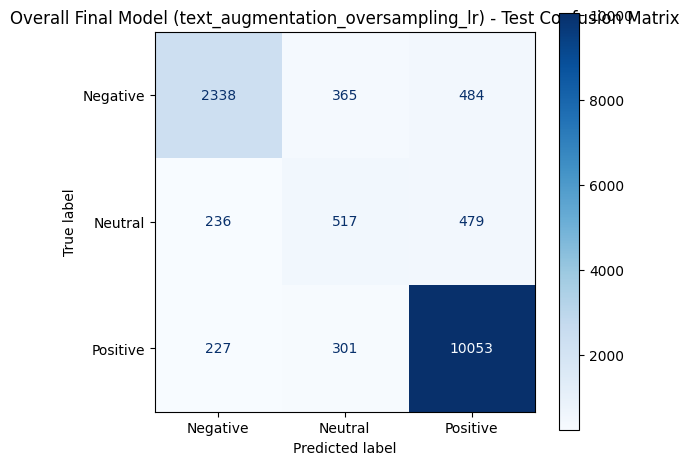

In [ ]:
strategy_registry_all = {
    "class_weight_balanced_lr": {"model": strategies["class_weight_balanced"], "X_test": X_test},
    "smote_lr": {"model": smote_pipeline, "X_test": test_df["review_clf_ml"]},
    "smote_plus_class_weight_lr": {"model": strategies["smote_plus_class_weight"], "X_test": test_df["review_clf_ml"]},
    "text_augmentation_oversampling_lr": {"model": model_aug, "X_test": tfidf_aug.transform(test_df["review_clf_ml"])},
    "class_weight_balanced_svc": {"model": strategies_svc["class_weight_balanced_svc"], "X_test": X_test},
    "smote_svc": {"model": smote_pipeline_svc, "X_test": test_df["review_clf_ml"]},
    "smote_plus_class_weight_svc": {"model": strategies_svc["smote_plus_class_weight_svc"], "X_test": test_df["review_clf_ml"]},
    "text_augmentation_oversampling_svc": {"model": model_aug_svc, "X_test": tfidf_aug.transform(test_df["review_clf_ml"])},
}

final_model_all = strategy_registry_all[best_strategy_name_all]["model"]
final_X_test_all = strategy_registry_all[best_strategy_name_all]["X_test"]

y_test_pred_final_all = final_model_all.predict(final_X_test_all)

print(f"OVERALL FINAL model ({best_strategy_name_all}) - Test set classification report:\n")
print(classification_report(y_test, y_test_pred_final_all, labels=CLASS_LABELS, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_final_all, labels=CLASS_LABELS, cmap="Blues", ax=ax, values_format="d"
)
ax.set_title(f"Overall Final Model ({best_strategy_name_all}) - Test Confusion Matrix")
plt.tight_layout()
plt.show()


### 15.4 Reality Check

If the scoreboard in 15.2 shows all strategies clustered within a point or two of each other (a common outcome), that's the data telling you resampling strategy isn't the bottleneck -- class separability is. At that point, per our Section 14.5 discussion, the next real lever is a fine-tuned transformer with a weighted loss, not another resampling variant. Run this section once, look at the scoreboard honestly, and let it decide the next step rather than continuing to swap resampling techniques.

## 16. Master Model Comparison (All Trained Models, Test Set)

Every model trained in this notebook, evaluated the same way on the same
held-out test set, so Logistic Regression and Linear SVC can be compared
head-to-head at every stage of the pipeline (baseline, threshold-tuned,
richer features, and the overall winner).

In [ ]:
master_results = []

def add_result(name, y_true, y_pred):
    master_results.append({
        "model": name,
        "accuracy": (y_pred == y_true).mean(),
        "macro_f1": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="weighted"),
        f"{MINORITY_CLASS}_f1": f1_score(y_true, y_pred, labels=[MINORITY_CLASS], average="macro"),
    })

add_result("LogReg - baseline (class_weight)", y_test, y_test_pred)
add_result("LinearSVC - baseline (class_weight)", y_test, y_test_pred_svc)
add_result("LogReg - tuned threshold", y_test, y_test_pred_tuned)
add_result("LinearSVC - tuned threshold (calibrated)", y_test, y_test_pred_tuned_svc)
add_result("LogReg - word+char TF-IDF", y_test, y_test_pred_combined)
add_result("LinearSVC - word+char TF-IDF", y_test, y_test_pred_combined_svc)
add_result(f"Overall best strategy ({best_strategy_name_all})", y_test, y_test_pred_final_all)

master_df = pd.DataFrame(master_results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
master_df


,model,accuracy,macro_f1,weighted_f1,Neutral_f1
0,Overall best strategy (text_augmentation_overs...,0.860533,0.713338,0.857781,0.428157
1,LogReg - baseline (class_weight),0.825467,0.701162,0.840005,0.422857
2,LogReg - tuned threshold,0.825000,0.700647,0.839676,0.421842
3,LinearSVC - word+char TF-IDF,0.851600,0.700151,0.851899,0.394758
4,LogReg - word+char TF-IDF,0.826400,0.699085,0.840309,0.415002
5,LinearSVC - tuned threshold (calibrated),0.850067,0.697846,0.849272,0.400627
6,LinearSVC - baseline (class_weight),0.849267,0.696307,0.850324,0.385233


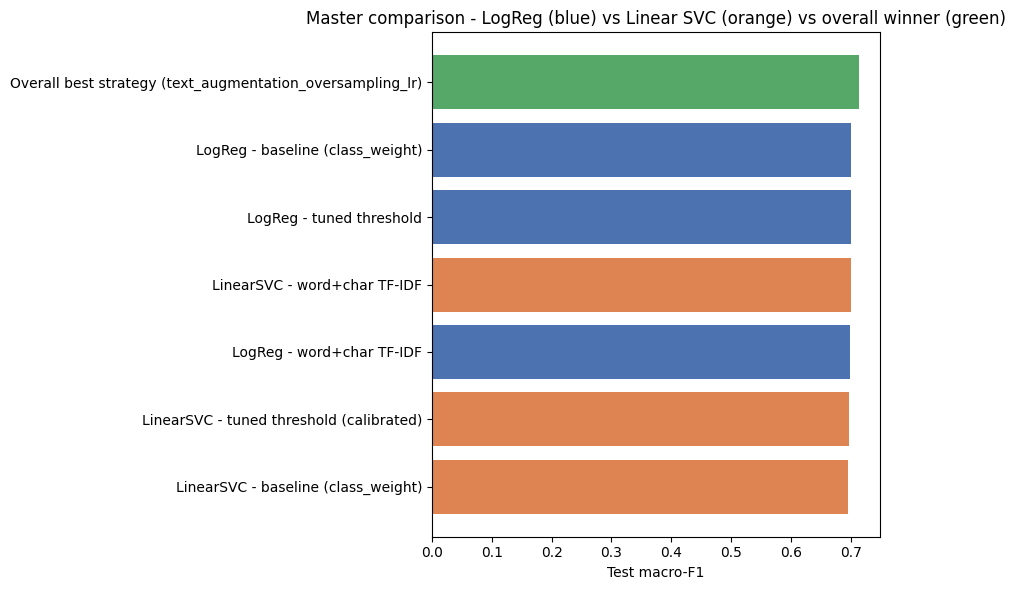

In [ ]:
plt.figure(figsize=(9, 6))
order = master_df.sort_values("macro_f1")
colors = ["#4C72B0" if "LogReg" in name else ("#DD8452" if "LinearSVC" in name else "#55A868")
          for name in order["model"]]
plt.barh(order["model"], order["macro_f1"], color=colors)
plt.xlabel("Test macro-F1")
plt.title("Master comparison - LogReg (blue) vs Linear SVC (orange) vs overall winner (green)")
plt.tight_layout()
plt.show()


## 12c. Model Training (Complement Naive Bayes)

Same features, same split, same imbalance-aware intent as the Logistic Regression (Section 12) and Linear SVC (Section 12b) baselines -- only the estimator changes. `ComplementNB` is a variant of Multinomial Naive Bayes specifically designed for **imbalanced text classification**: it estimates each class's parameters from the complement of that class (all *other* classes), which corrects the bias standard Naive Bayes has toward majority classes on skewed data. It has no `class_weight` parameter, so we reproduce the same 'weight minority classes more' intent using `sample_weight` at fit time, computed the same way as the class weights in Section 11.

In [ ]:
# ---------------------------------------------------------------------------
# Train a Complement Naive Bayes classifier on the same TF-IDF features
# (Section 10) used for Logistic Regression and Linear SVC.
# - ComplementNB has no class_weight arg, so we emulate class_weight="balanced"
#   via sample_weight, computed identically to Section 11's weighting scheme
# - alpha is Laplace/Lidstone smoothing (default 1.0, standard choice for text)
# - norm=True applies the second normalization step from the Complement NB
#   paper, which typically improves accuracy on text data
# ---------------------------------------------------------------------------
from sklearn.naive_bayes import ComplementNB
from sklearn.utils.class_weight import compute_sample_weight

train_sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

nb_model = ComplementNB(alpha=1.0, norm=True)
nb_model.fit(X_train, y_train, sample_weight=train_sample_weights)

print("Model trained.")
print("Classes learned by the model:", nb_model.classes_)


Model trained.
Classes learned by the model: ['Negative' 'Neutral' 'Positive']


## 13c. Evaluation (Complement Naive Bayes)

Same evaluation protocol as Sections 13 and 13b: held-out **test set**, full `classification_report`, and raw + row-normalized confusion matrices.

In [ ]:
# ---------------------------------------------------------------------------
# Predict on the test set and print the classification report
# ---------------------------------------------------------------------------
y_test_pred_nb = nb_model.predict(X_test)

print("Classification Report (Test set) - Complement Naive Bayes:\n")
print(classification_report(y_test, y_test_pred_nb, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Complement Naive Bayes:

              precision    recall  f1-score   support

    Negative      0.680     0.779     0.727      3187
     Neutral      0.223     0.670     0.334      1232
    Positive      0.979     0.707     0.821     10581

    accuracy                          0.719     15000
   macro avg      0.627     0.719     0.627     15000
weighted avg      0.853     0.719     0.761     15000



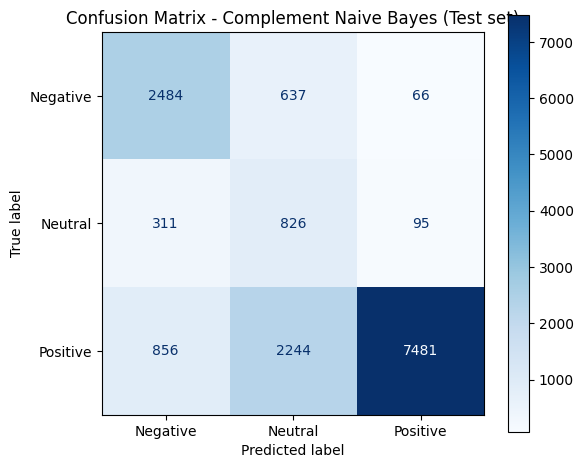

In [ ]:
# ---------------------------------------------------------------------------
# Visual confusion matrix (raw counts) - Complement Naive Bayes
# ---------------------------------------------------------------------------
cm_nb = confusion_matrix(y_test, y_test_pred_nb, labels=CLASS_LABELS)

fig, ax = plt.subplots(figsize=(6, 5))
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=CLASS_LABELS)
disp_nb.plot(cmap="Blues", ax=ax, colorbar=True, values_format="d")
ax.set_title("Confusion Matrix - Complement Naive Bayes (Test set)")
plt.tight_layout()
plt.show()


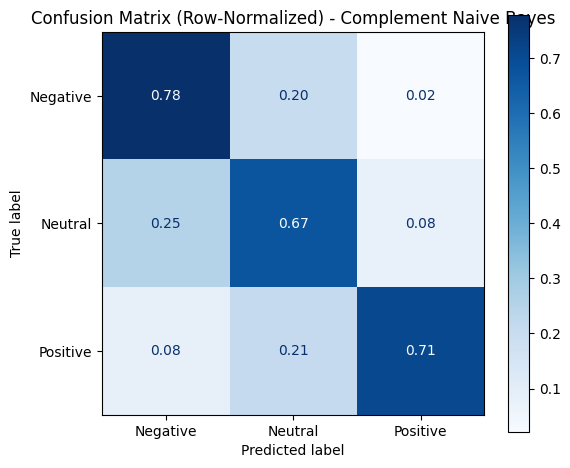

In [ ]:
# ---------------------------------------------------------------------------
# Normalized confusion matrix (row-normalized -> recall per class) - CNB
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
disp_nb_norm = ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_nb, labels=CLASS_LABELS, normalize="true",
    cmap="Blues", ax=ax, values_format=".2f",
)
ax.set_title("Confusion Matrix (Row-Normalized) - Complement Naive Bayes")
plt.tight_layout()
plt.show()


### 13d. Three-Way Comparison: Logistic Regression vs Linear SVC vs Complement Naive Bayes

Extends the 13c comparison to all three baseline estimators on the same test set, using macro-F1 and weighted-F1 so class imbalance doesn't hide in a single accuracy number.

In [ ]:
# ---------------------------------------------------------------------------
# Compare Logistic Regression vs Linear SVC vs Complement Naive Bayes
# ---------------------------------------------------------------------------
three_way_comparison_df = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "accuracy": (y_test_pred == y_test).mean(),
        "macro_f1": f1_score(y_test, y_test_pred, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_test, y_test_pred, labels=CLASS_LABELS, average="weighted"),
    },
    {
        "model": "Linear SVC",
        "accuracy": (y_test_pred_svc == y_test).mean(),
        "macro_f1": f1_score(y_test, y_test_pred_svc, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_test, y_test_pred_svc, labels=CLASS_LABELS, average="weighted"),
    },
    {
        "model": "Complement Naive Bayes",
        "accuracy": (y_test_pred_nb == y_test).mean(),
        "macro_f1": f1_score(y_test, y_test_pred_nb, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_test, y_test_pred_nb, labels=CLASS_LABELS, average="weighted"),
    },
]).sort_values("macro_f1", ascending=False).reset_index(drop=True)

three_way_comparison_df


,model,accuracy,macro_f1,weighted_f1
0,Logistic Regression,0.825467,0.701162,0.840005
1,Linear SVC,0.849267,0.696307,0.850324
2,Complement Naive Bayes,0.719400,0.627353,0.761004


### 14.1c SMOTE + Complement Naive Bayes (same pipeline, swapped estimator)

Identical `imblearn` pipeline as 14.1/14.1b -- same TF-IDF settings, same `smote_k`, same train-fold-only resampling -- with `ComplementNB` in place of Logistic Regression / Linear SVC.

In [ ]:
smote_pipeline_nb = ImbPipeline(steps=[
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.9,
        sublinear_tf=True,
    )),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
    ("clf", ComplementNB(alpha=1.0, norm=True)),
])

smote_pipeline_nb.fit(train_df["review_clf_ml"], y_train)

y_val_pred_smote_nb = smote_pipeline_nb.predict(val_df["review_clf_ml"])
print("Validation results - TF-IDF + SMOTE + Complement Naive Bayes:\n")
print(classification_report(y_val, y_val_pred_smote_nb, labels=CLASS_LABELS, digits=3))


Validation results - TF-IDF + SMOTE + Complement Naive Bayes:

              precision    recall  f1-score   support

    Negative      0.675     0.723     0.698      3186
     Neutral      0.201     0.722     0.314      1233
    Positive      0.981     0.663     0.792     10581

    accuracy                          0.681     15000
   macro avg      0.619     0.703     0.601     15000
weighted avg      0.852     0.681     0.732     15000



### 14.2c Cross-validated comparison (Naive Bayes side): `sample_weight` vs SMOTE

Same comparison logic as 14.2/14.2b, run with `ComplementNB` (using `sample_weight` in place of `class_weight`), merged into one table with the LR and SVC results.

In [ ]:
strategies_nb = {
    "class_weight_balanced_nb": nb_model,  # already fit in Section 12c with sample_weight
    "smote_only_nb": None,  # handled via smote_pipeline_nb above
    "smote_plus_class_weight_nb": ImbPipeline(steps=[
        ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
        ("clf", ComplementNB(alpha=1.0, norm=True)),
    ]),
}

results_nb = {}
pred = strategies_nb["class_weight_balanced_nb"].predict(X_val)
results_nb["class_weight_balanced_nb"] = f1_score(y_val, pred, labels=CLASS_LABELS, average=None)

results_nb["smote_only_nb"] = f1_score(y_val, y_val_pred_smote_nb, labels=CLASS_LABELS, average=None)

strategies_nb["smote_plus_class_weight_nb"].fit(train_df["review_clf_ml"], y_train)
pred = strategies_nb["smote_plus_class_weight_nb"].predict(val_df["review_clf_ml"])
results_nb["smote_plus_class_weight_nb"] = f1_score(y_val, pred, labels=CLASS_LABELS, average=None)

comparison_nb_df = pd.DataFrame(results_nb, index=CLASS_LABELS).T
comparison_nb_df.columns = [f"F1_{c}" for c in CLASS_LABELS]
comparison_nb_df["F1_macro"] = comparison_nb_df.mean(axis=1)
comparison_nb_df.sort_values("F1_macro", ascending=False)


,F1_Negative,F1_Neutral,F1_Positive,F1_macro
class_weight_balanced_nb,0.714684,0.331472,0.817767,0.621307
smote_only_nb,0.697879,0.314155,0.791587,0.601207
smote_plus_class_weight_nb,0.697879,0.314155,0.791587,0.601207


### 14.3c Threshold Tuning for Complement Naive Bayes

Unlike `LinearSVC` (14.3b), `ComplementNB` has a **native** `predict_proba`, so no `CalibratedClassifierCV` wrapper is needed here -- the same threshold-sweep-and-apply workflow from 14.3 runs directly on `nb_model`'s own probability estimates.

In [ ]:
val_probs_nb = nb_model.predict_proba(X_val)[:, list(nb_model.classes_).index(MINORITY_CLASS)]

precisions_nb, recalls_nb, thresholds_nb = precision_recall_curve(y_val_binary, val_probs_nb)
f1_scores_nb = 2 * (precisions_nb * recalls_nb) / (precisions_nb + recalls_nb + 1e-12)

best_idx_nb = np.nanargmax(f1_scores_nb[:-1])
best_threshold_nb = thresholds_nb[best_idx_nb]
print(f"Best threshold for '{MINORITY_CLASS}' (Complement Naive Bayes): {best_threshold_nb:.3f} "
      f"(F1={f1_scores_nb[best_idx_nb]:.3f} vs default 0.5)")


Best threshold for 'Neutral' (Complement Naive Bayes): 0.333 (F1=0.400 vs default 0.5)


In [ ]:
minority_idx_nb = list(nb_model.classes_).index(MINORITY_CLASS)

y_test_pred_tuned_nb = predict_with_minority_threshold(
    nb_model, X_test, MINORITY_CLASS, minority_idx_nb, best_threshold_nb, CLASS_LABELS
)

print("Classification Report (Test set) - Complement Naive Bayes WITH tuned minority threshold:\n")
print(classification_report(y_test, y_test_pred_tuned_nb, labels=CLASS_LABELS, digits=3))

print("\nFor comparison, Complement Naive Bayes WITHOUT threshold tuning (default 0.5 argmax):\n")
print(classification_report(y_test, y_test_pred_nb, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Complement Naive Bayes WITH tuned minority threshold:

              precision    recall  f1-score   support

    Negative      0.680     0.763     0.720      3187
     Neutral      0.221     0.679     0.333      1232
    Positive      0.979     0.707     0.821     10581

    accuracy                          0.717     15000
   macro avg      0.627     0.716     0.625     15000
weighted avg      0.853     0.717     0.759     15000


For comparison, Complement Naive Bayes WITHOUT threshold tuning (default 0.5 argmax):

              precision    recall  f1-score   support

    Negative      0.680     0.779     0.727      3187
     Neutral      0.223     0.670     0.334      1232
    Positive      0.979     0.707     0.821     10581

    accuracy                          0.719     15000
   macro avg      0.627     0.719     0.627     15000
weighted avg      0.853     0.719     0.761     15000



### 14.4c Combined Word + Char TF-IDF with Complement Naive Bayes

Same `combined_features` (word 1-2gram + char 3-5gram `FeatureUnion`) from 14.4/14.4b, `ComplementNB` in place of Logistic Regression / Linear SVC.

In [ ]:
combined_sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

combined_model_nb = ComplementNB(alpha=1.0, norm=True)
combined_model_nb.fit(X_train_combined, y_train, sample_weight=combined_sample_weights)

y_test_pred_combined_nb = combined_model_nb.predict(X_test_combined)
print("Classification Report (Test set) - Word + Char TF-IDF + Complement Naive Bayes:\n")
print(classification_report(y_test, y_test_pred_combined_nb, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - Word + Char TF-IDF + Complement Naive Bayes:

              precision    recall  f1-score   support

    Negative      0.676     0.772     0.721      3187
     Neutral      0.216     0.689     0.329      1232
    Positive      0.978     0.687     0.807     10581

    accuracy                          0.705     15000
   macro avg      0.623     0.716     0.619     15000
weighted avg      0.851     0.705     0.750     15000



### 15.1c Text-Augmentation Oversampling with Complement Naive Bayes

Same augmented training set (`train_df_augmented`, `X_train_aug`) from 15.1/15.1b, `ComplementNB` in place of Logistic Regression / Linear SVC.

In [ ]:
model_aug_nb = ComplementNB(alpha=1.0, norm=True)
model_aug_nb.fit(X_train_aug, y_train_aug)

y_val_pred_aug_nb = model_aug_nb.predict(X_val_aug)
print("Validation results - TF-IDF + Text-Augmentation Oversampling + Complement Naive Bayes:\n")
print(classification_report(y_val, y_val_pred_aug_nb, labels=CLASS_LABELS, digits=3))


Validation results - TF-IDF + Text-Augmentation Oversampling + Complement Naive Bayes:

              precision    recall  f1-score   support

    Negative      0.743     0.794     0.768      3186
     Neutral      0.389     0.405     0.397      1233
    Positive      0.935     0.911     0.923     10581

    accuracy                          0.844     15000
   macro avg      0.689     0.703     0.696     15000
weighted avg      0.849     0.844     0.846     15000



### 15.2c Extended Scoreboard: All 12 Strategies (LR + Linear SVC + Complement Naive Bayes)

Every strategy trained across all three estimator families, scored the same way (validation macro-F1 and minority-class F1) in one table.

In [ ]:
strategy_val_predictions_full = dict(strategy_val_predictions_all)  # from 15.2b: 8 LR + SVC strategies
strategy_val_predictions_full.update({
    "class_weight_balanced_nb": strategies_nb["class_weight_balanced_nb"].predict(X_val),
    "smote_nb": y_val_pred_smote_nb,
    "smote_plus_class_weight_nb": strategies_nb["smote_plus_class_weight_nb"].predict(val_df["review_clf_ml"]),
    "text_augmentation_oversampling_nb": y_val_pred_aug_nb,
})

scoreboard_full = []
for name, preds in strategy_val_predictions_full.items():
    macro_f1 = f1_score(y_val, preds, labels=CLASS_LABELS, average="macro")
    minority_f1 = f1_score(y_val, preds, labels=[MINORITY_CLASS], average="macro")
    scoreboard_full.append({"strategy": name, "macro_f1": macro_f1, f"{MINORITY_CLASS}_f1": minority_f1})

scoreboard_full_df = pd.DataFrame(scoreboard_full).sort_values("macro_f1", ascending=False).reset_index(drop=True)
scoreboard_full_df


,strategy,macro_f1,Neutral_f1
0,text_augmentation_oversampling_lr,0.706489,0.420629
1,class_weight_balanced_lr,0.695977,0.413467
2,text_augmentation_oversampling_nb,0.695587,0.396504
3,class_weight_balanced_svc,0.694571,0.389671
4,smote_plus_class_weight_lr,0.694198,0.413202
5,smote_lr,0.694198,0.413202
6,text_augmentation_oversampling_svc,0.687609,0.377138
7,smote_svc,0.673035,0.368457
8,smote_plus_class_weight_svc,0.673035,0.368457
9,class_weight_balanced_nb,0.621307,0.331472


### 15.3c Final Model, Re-selected Across LR + Linear SVC + Complement Naive Bayes

Same re-apply-the-winner logic as 15.3/15.3b, now choosing from all 12 strategies across all three estimator families.

In [ ]:
strategy_registry_full = dict(strategy_registry_all)  # from 15.3b: 8 LR + SVC entries
strategy_registry_full.update({
    "class_weight_balanced_nb": {"model": strategies_nb["class_weight_balanced_nb"], "X_test": X_test},
    "smote_nb": {"model": smote_pipeline_nb, "X_test": test_df["review_clf_ml"]},
    "smote_plus_class_weight_nb": {"model": strategies_nb["smote_plus_class_weight_nb"], "X_test": test_df["review_clf_ml"]},
    "text_augmentation_oversampling_nb": {"model": model_aug_nb, "X_test": tfidf_aug.transform(test_df["review_clf_ml"])},
})

best_strategy_name_full = scoreboard_full_df.loc[0, "strategy"]
final_model_full = strategy_registry_full[best_strategy_name_full]["model"]
final_X_test_full = strategy_registry_full[best_strategy_name_full]["X_test"]

y_test_pred_final_full = final_model_full.predict(final_X_test_full)

print(f"FINAL model across all 3 estimator families ({best_strategy_name_full}) - Test set classification report:\n")
print(classification_report(y_test, y_test_pred_final_full, labels=CLASS_LABELS, digits=3))


FINAL model across all 3 estimator families (text_augmentation_oversampling_lr) - Test set classification report:

              precision    recall  f1-score   support

    Negative      0.835     0.734     0.781      3187
     Neutral      0.437     0.420     0.428      1232
    Positive      0.913     0.950     0.931     10581

    accuracy                          0.861     15000
   macro avg      0.728     0.701     0.713     15000
weighted avg      0.857     0.861     0.858     15000



## 16b. Master Model Comparison Update: Adding Complement Naive Bayes

Extends Section 16's `master_results` with every Complement Naive Bayes variant trained above, so Logistic Regression, Linear SVC, and Complement Naive Bayes can all be compared head-to-head at every stage of the pipeline on the identical held-out test set.

In [ ]:
add_result("NaiveBayes_baseline", y_test, y_test_pred_nb)
add_result("NaiveBayes_threshold_tuned", y_test, y_test_pred_tuned_nb)
add_result("NaiveBayes_word_char_features", y_test, y_test_pred_combined_nb)
add_result(f"NaiveBayes_final_{best_strategy_name_full}", y_test, y_test_pred_final_full)

master_df = pd.DataFrame(master_results)
master_df


,model,accuracy,macro_f1,weighted_f1,Neutral_f1
0,LogReg - baseline (class_weight),0.825467,0.701162,0.840005,0.422857
1,LinearSVC - baseline (class_weight),0.849267,0.696307,0.850324,0.385233
2,LogReg - tuned threshold,0.825000,0.700647,0.839676,0.421842
3,LinearSVC - tuned threshold (calibrated),0.850067,0.697846,0.849272,0.400627
4,LogReg - word+char TF-IDF,0.826400,0.699085,0.840309,0.415002
5,LinearSVC - word+char TF-IDF,0.851600,0.700151,0.851899,0.394758
6,Overall best strategy (text_augmentation_overs...,0.860533,0.713338,0.857781,0.428157
7,NaiveBayes_baseline,0.719400,0.627353,0.761004,0.334481
8,NaiveBayes_threshold_tuned,0.716667,0.624666,0.759454,0.333400
9,NaiveBayes_word_char_features,0.705333,0.619060,0.749504,0.329325


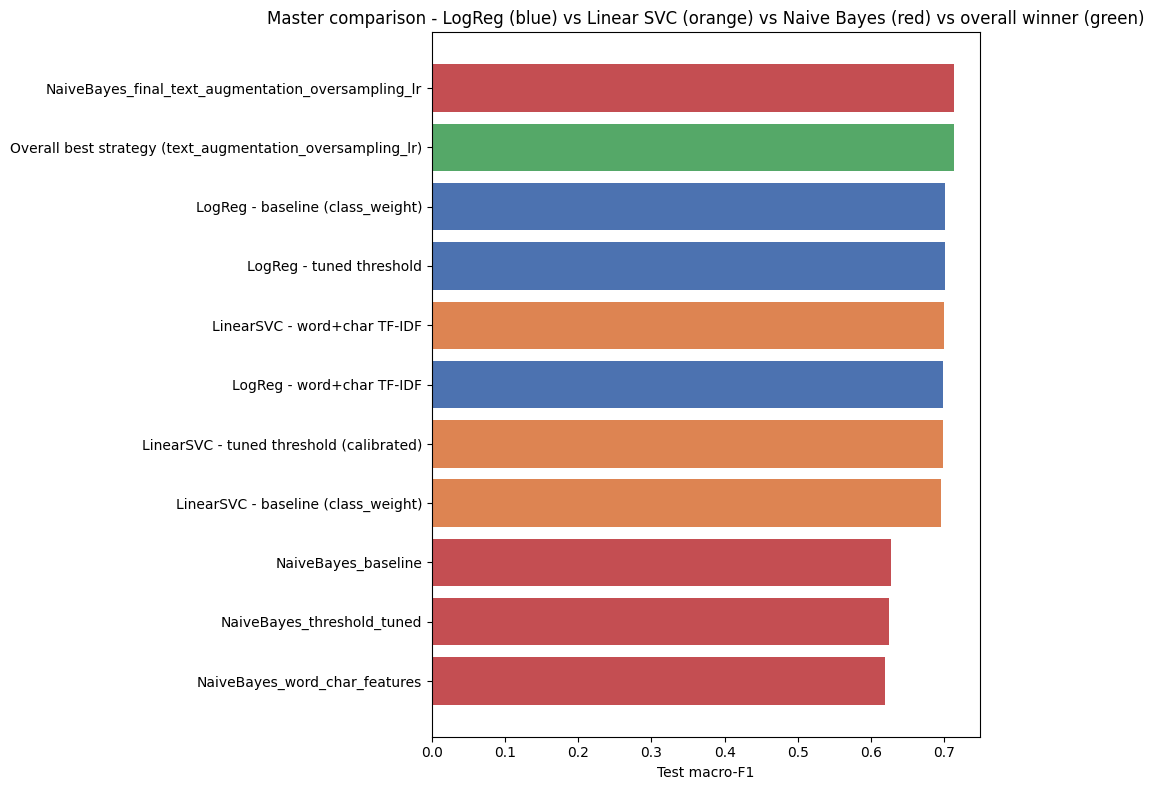

In [ ]:
plt.figure(figsize=(10, 8))
order_full = master_df.sort_values("macro_f1")

def bar_color(name):
    if "LogReg" in name:
        return "#4C72B0"
    if "LinearSVC" in name:
        return "#DD8452"
    if "NaiveBayes" in name:
        return "#C44E52"
    return "#55A868"

colors_full = [bar_color(name) for name in order_full["model"]]
plt.barh(order_full["model"], order_full["macro_f1"], color=colors_full)
plt.xlabel("Test macro-F1")
plt.title("Master comparison - LogReg (blue) vs Linear SVC (orange) vs Naive Bayes (red) vs overall winner (green)")
plt.tight_layout()
plt.show()
